# Part 2 of 4: Baselines and deep baseline
**Project:** How High Will Gas Prices Get Tomorrow? · **Team:** Orville Rockwell Jr., Yi-Ting Lin, Wenjun Chen, Yixin Tian

**Owner:** Wenjun Chen

Builds the baselines (persistence, momentum, error-correction), then the Gaussian LSTM and GARCH-LSTM-t on 10 years of weekly data and on the daily Kalshi labels.

**Your task:** improve this part in 5 specific ways. Put each in a Markdown cell titled **Revision** (what you changed, why, and the result), and keep a log of what you did and when for the contribution table.

## Setup (run this cell first, every time)
It installs any missing packages, then writes the project code (`gaslab/`) and the real data (`data/`) into this
notebook's folder **only if they are not there yet**. If you edit a file in `gaslab/` or drop newer CSVs in `data/`,
re-running this cell will not overwrite them. Data: EIA/FRED weekly retail and daily wholesale and crude prices
from Jan 2014 to Oct 2026, plus every settled Kalshi AAA gas contract (the daily AAA labels), and the AAA national daily average from
June 2015 to November 2026 recovered from Wayback Machine snapshots of gasprices.aaa.com (`manual_aaa.csv`).

#### ▶ What the next cell does: quick look at a FRED price series (exploratory, not used by the model)

Downloads the FRED series `DCOILWTICO` (daily WTI crude oil spot price) for Sep 1 2015 – Aug 31 2026 straight from the FRED website, renames the columns to `date` and `gas_price`, converts the dates, and prints the first rows and the table size. It then counts the calendar days between the two dates.

**Output:** the first five rows, the shape (2,870 trading days × 2 columns) and the number of calendar days (4,017). Missing values (`NaN`) are market holidays, such as Sep 7 2015 (Labor Day).

**Note:** `DCOILWTICO` is the **WTI crude oil price in dollars per barrel**, not a gasoline price, so the column name `gas_price` is misleading. This cell needs an internet connection, and nothing later in the notebook uses `df`: the model reads its data from `data/fred.csv`, written by the Setup cell. `df.tail()` in the middle of the cell shows nothing, because Jupyter only displays the last expression of a cell.

In [1]:
import pandas as pd

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILWTICO&cosd=2015-09-01&coed=2026-08-31"
df = pd.read_csv(url)
df.columns = ['date', 'gas_price']
df['date'] = pd.to_datetime(df['date'])

print(df.head())
print(df.shape)
df.tail()
from datetime import date
start = date(2015, 9, 1)
end = date(2026, 8, 31)
print((end - start).days)

        date  gas_price
0 2015-09-01      45.38
1 2015-09-02      46.30
2 2015-09-03      46.75
3 2015-09-04      46.02
4 2015-09-07        NaN
(2870, 2)
4017


#### ▶ What the next cell does: Setup: install packages, write the project code and the data

1. Checks whether `arch`, `statsmodels`, `scikit-learn`, `tensorflow`, `matplotlib` and `scipy` are installed and installs any that are missing.
2. `CODE` holds the source of every project module as text. The cell writes them to `gaslab/` (`data.py`, `models.py`, `evaluate.py`, `pipeline.py`, `experiments.py`, `handoff.py`, …). If `gaslab/` holds an older version of the code, it is first backed up to `gaslab_backup_<version>/` and then replaced.
3. `DATA` holds the five data files encoded as base64 text. They are decoded and written to `data/`: `fred.csv` (EIA/FRED retail, wholesale and crude prices), `kalshi_markets.csv` (every Kalshi AAA gas contract), `kalshi_open_book.csv` (bid/ask at the open), `manual_aaa.csv` (AAA national daily average, Jun 2015 – Nov 2026, from Wayback Machine snapshots of gasprices.aaa.com) and `manual_aaa_sources.csv` (where each AAA value came from: observed on the page, or read from its week-, month- or year-ago row).
4. Files that already exist are never overwritten, so your own edits and newer data are kept.

**Output:** the list of code files and the size of each data file. The cell is very long because the code and data are stored inside it, which is what lets the notebook run on its own.

In [2]:
import sys, os, base64, shutil, subprocess, importlib.util
need = [pkg for pkg, mod in [("arch", "arch"), ("statsmodels", "statsmodels"), ("scikit-learn", "sklearn"),
                             ("tensorflow", "tensorflow"), ("matplotlib", "matplotlib"), ("scipy", "scipy")]
        if importlib.util.find_spec(mod) is None]
if need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need]); print("installed:", need)
VERSION = '2026-11-04'
CODE = {'__init__.py': '', 'data.py': '"""Data layer: FRED wholesale/crude/retail + Kalshi AAA settlements -> leak-free feature tensors.\n\nTiming conventions (all decisions are made with information available at the bid time):\n  * Weekly model: origin = Monday t (EIA retail R_t surveyed 8 a.m. Monday). Target = log(R_{t+1}/R_t).\n    Wholesale/crude inputs use closes through the Friday before Monday t.\n  * Daily model: origin = 8:00 a.m. ET on day D-1, when Kalshi opens the contract settling on day D.\n    AAA\'s D-1 average is already posted (Kalshi centres the strike ladder on it). Wholesale/crude\n    inputs use closes through business day D-2. Target = log(A_D/A_{D-1}).\n"""\nfrom pathlib import Path\nimport numpy as np, pandas as pd\n\nDATA = Path(__file__).resolve().parent.parent / "data"\nGAL_PER_BBL = 42.0\n\n\ndef load_fred():\n    f = pd.read_csv(DATA / "fred.csv", parse_dates=["date"]).set_index("date").sort_index()\n    f["wti"] /= GAL_PER_BBL; f["brent"] /= GAL_PER_BBL            # $/bbl -> $/gal\n    f.loc[f["wti"] <= 0, "wti"] = np.nan                           # 2020-04-20 negative WTI print\n    return f\n\n\ndef load_aaa_daily():\n    """AAA national regular average by date, from Kalshi settlement values plus any manual rows."""\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series.isin(["KXAAAGASD", "KXAAAGASW", "KXAAAGASM"])].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["value"] = pd.to_numeric(k.value, errors="coerce")\n    s = k.dropna(subset=["value"]).groupby("date").value.first()\n    manual = DATA / "manual_aaa.csv"                               # optional: date,aaa\n    if manual.exists():\n        m = pd.read_csv(manual, parse_dates=["date"]).set_index("date")["aaa"]\n        s = pd.concat([s, m]).groupby(level=0).last()\n    return s.sort_index().rename("aaa")\n\n\ndef daily_contracts(series="KXAAAGASD"):\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series == series].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["y"] = (k.result == "yes").astype(float).where(k.result.isin(["yes", "no"]))\n    book = DATA / "kalshi_open_book.csv"\n    if book.exists():\n        k = k.merge(pd.read_csv(book)[["ticker", "bid", "ask", "hours_after_open"]], on="ticker", how="left")\n    return k\n\n\n# ----------------------------------------------------------------------------------- weekly (10 years)\nWEEKLY_FEATS = ["d_retail", "d_gulf", "d_nyh", "d_brent", "up_gulf", "dn_gulf", "ect", "garch_sd"]\n\n\ndef weekly_frame(f=None):\n    """One row per EIA Monday t with features known at t and target y = log(R_{t+1}/R_t)."""\n    f = load_fred() if f is None else f\n    r = f["retail_eia_weekly"].dropna()\n    bd = f[["whsl_gulf", "whsl_nyh", "brent"]].ffill()\n    rows = []\n    for t in r.index:\n        fri = bd.loc[: t - pd.Timedelta(days=3)].tail(5)            # Mon-Fri week ending the Friday before t\n        if len(fri) < 5: continue\n        rows.append(dict(date=t, retail=r.loc[t], gulf=fri.whsl_gulf.mean(), nyh=fri.whsl_nyh.mean(), brent=fri.brent.mean()))\n    w = pd.DataFrame(rows).set_index("date")\n    lw = np.log(w)\n    w["d_retail"] = lw.retail.diff(); w["d_gulf"] = lw.gulf.diff(); w["d_nyh"] = lw.nyh.diff(); w["d_brent"] = lw.brent.diff()\n    w["up_gulf"] = w.d_gulf.clip(lower=0); w["dn_gulf"] = w.d_gulf.clip(upper=0)         # rockets & feathers\n    spread = lw.retail - lw.gulf                                                          # retail margin (log)\n    w["ect"] = spread - spread.rolling(52, min_periods=26).mean()                        # error-correction term\n    w["y"] = w.d_retail.shift(-1)\n    return w\n\n\n# ----------------------------------------------------------------------------------- daily (Kalshi)\nDAILY_FEATS = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift", "garch_sd"]\n\n\ndef daily_frame(f=None, aaa=None, weekly_drift=None, extend_to=None):\n    """One row per settlement day D with features known at 8 a.m. ET on D-1.\n    extend_to adds future settlement dates (no target yet) so live contracts can be priced."""\n    f = load_fred() if f is None else f\n    aaa = load_aaa_daily() if aaa is None else aaa\n    a = aaa.asfreq("D")\n    if extend_to is not None and pd.Timestamp(extend_to) > a.index[-1]:\n        a = a.reindex(pd.date_range(a.index[0], extend_to, freq="D"))\n    bd = f[["whsl_gulf", "brent"]].ffill().asfreq("D").reindex(a.index.union(f.index)).ffill().reindex(a.index)\n    df = pd.DataFrame(index=a.index)\n    df["aaa_prev"] = a.shift(1)                                          # A_{D-1}\n    df["d_aaa"] = np.log(a).diff().shift(1)                              # change into D-1\n    df["d_aaa_l2"] = df["d_aaa"].shift(1)                                # change into D-2\n    g2 = np.log(bd.whsl_gulf).shift(2); b2 = np.log(bd.brent).shift(2)   # closes through D-2\n    df["d_gulf"] = g2.diff(); df["d_brent"] = b2.diff()\n    spread = np.log(df.aaa_prev) - g2.rolling(5).mean()\n    df["ect"] = spread - spread.rolling(28, min_periods=10).mean()\n    df["w_drift"] = 0.0 if weekly_drift is None else weekly_drift.reindex(df.index, method="ffill").fillna(0) / 7.0\n    df["y"] = np.log(a).diff()\n    return df\n\n\ndef sequences(df, feats, lookback, rows=None, allow_missing_y=()):\n    """Stack rolling windows of features ending at each row. Returns X, y, index.\n    Rows listed in allow_missing_y are kept even without a target (used for live forecasts)."""\n    vals = df[feats].values.astype("float32"); ys = df["y"].values.astype("float32")\n    idx = []; X = []; Y = []\n    want = set(df.index if rows is None else rows)\n    for i in range(lookback - 1, len(df)):\n        if df.index[i] not in want: continue\n        win = vals[i - lookback + 1: i + 1]\n        if np.isnan(win).any() or (np.isnan(ys[i]) and df.index[i] not in allow_missing_y): continue\n        X.append(win); Y.append(ys[i]); idx.append(df.index[i])\n    return np.array(X), np.array(Y), pd.DatetimeIndex(idx)\n', 'evaluate.py': '"""Scoring: distribution metrics, Kalshi strike-ladder pricing, accuracy variants, and a fee-aware backtest."""\nimport numpy as np, pandas as pd\nfrom scipy import stats\n\n\ndef cdf(x, mu, scale, df):\n    z = (x - mu) / scale\n    return np.where(np.isinf(df), stats.norm.cdf(z), stats.t.cdf(z, np.where(np.isinf(df), 30, df)))\n\n\ndef logpdf(y, mu, scale, df):\n    z = (y - mu) / scale\n    return np.where(np.isinf(df), stats.norm.logpdf(z), stats.t.logpdf(z, np.where(np.isinf(df), 30, df))) - np.log(scale)\n\n\ndef crps_mc(y, mu, scale, df, n=2000, seed=0):\n    rng = np.random.default_rng(seed); z = rng.standard_normal((n, len(y)))\n    t = np.where(np.isinf(df), z, rng.standard_t(np.where(np.isinf(df), 30, df), size=(n, len(y))))\n    s = mu + scale * t; s2 = mu + scale * np.roll(t, 1, axis=0)\n    return np.mean(np.abs(s - y), 0) - 0.5 * np.mean(np.abs(s - s2), 0)\n\n\ndef dist_metrics(y_pct, d):\n    mu, sc, nu = d.mu.values, d.scale.values, d.df.values\n    nz = y_pct != 0\n    return {"NLL": float(-logpdf(y_pct, mu, sc, nu).mean()),\n            "CRPS": float(crps_mc(y_pct, mu, sc, nu).mean()),\n            "MAE": float(np.abs(y_pct - mu).mean()),\n            "dir_acc": float((np.sign(mu[nz]) == np.sign(y_pct[nz])).mean()) if np.any(mu != 0) else np.nan,\n            "cov80": float(np.mean(np.abs(cdf(y_pct, mu, sc, nu) - 0.5) <= 0.4)),\n            "n": int(len(y_pct))}\n\n\ndef price_ladder(contracts, dist, prev_col="prev", extra_sd_pct=None):\n    """P(YES) = P(level_D > k) = 1 - F(100*ln(k/prev)). extra_sd_pct widens the scale (e.g. basis noise)."""\n    c = contracts.join(dist, on="date", how="inner")\n    sc = c.scale if extra_sd_pct is None else np.sqrt(c.scale ** 2 + extra_sd_pct ** 2)\n    x = 100 * np.log(c.strike / c[prev_col])\n    c["p"] = np.clip(1 - cdf(x, c.mu, sc, c.df), 1e-4, 1 - 1e-4)\n    return c\n\n\ndef contract_metrics(c, atm_cents=1.0):\n    y, p = c.y.values, c.p.values\n    atm = (np.abs(c.strike - c.prev) * 100 <= atm_cents).values\n    out = {"contracts": int(len(c)), "events": int(c.date.nunique()),\n           "accuracy": float(((p > 0.5) == (y == 1)).mean()),\n           "atm_accuracy": float(((p[atm] > 0.5) == (y[atm] == 1)).mean()) if atm.any() else np.nan,\n           "atm_n": int(atm.sum()),\n           "brier": float(np.mean((p - y) ** 2)),\n           "logloss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))}\n    return out\n\n\ndef kalshi_fee(price, rate=0.07):\n    """Kalshi taker fee per contract: rate * P * (1-P), rounded up to the centicent ($0.0001), per the Kalshi fee\n    schedule effective July 7, 2026. Resting (maker) orders on KXAAAGASD are not in the non-standard fee table,\n    so their maker multiplier defaults to 0 (no maker fee); this backtest conservatively assumes taker orders."""\n    return np.ceil(rate * price * (1 - price) * 10000 - 1e-9) / 10000\n\n\ndef backtest(c, edge=0.03):\n    """Take one contract per signal at the first-hour book after open. YES at ask, NO at (1-bid)."""\n    c = c.dropna(subset=["bid", "ask", "y"]).copy()\n    c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]\n    buy_yes = c.p - c.ask - kalshi_fee(c.ask) > edge\n    no_px = 1 - c.bid\n    buy_no = (1 - c.p) - no_px - kalshi_fee(no_px) > edge\n    pnl = np.where(buy_yes, c.y - c.ask - kalshi_fee(c.ask), 0.0) + np.where(buy_no, (1 - c.y) - no_px - kalshi_fee(no_px), 0.0)\n    trades = buy_yes | buy_no\n    c["pnl"] = pnl; c["trade"] = trades\n    cost = np.where(buy_yes, c.ask, 0) + np.where(buy_no, no_px, 0)\n    return {"trades": int(trades.sum()), "hit_rate": float((pnl[trades] > 0).mean()) if trades.any() else np.nan,\n            "pnl_per_contract": float(pnl[trades].mean()) if trades.any() else np.nan,\n            "total_pnl_$": float(pnl.sum()), "capital_$": float(cost.sum()),\n            "roi": float(pnl.sum() / cost.sum()) if cost.sum() else np.nan}, c\n\n\ndef market_metrics(c):\n    m = c.dropna(subset=["bid", "ask", "y"]).copy()\n    m["p"] = ((m.bid + m.ask) / 2).clip(0.005, 0.995)\n    return contract_metrics(m), m\n\n\ndef event_bootstrap(a, b, n=2000, seed=0):\n    """95% CIs that respect the small number of events: resample whole settlement days (all strikes of a day\n    move together), then recompute accuracy and Brier for signal a, signal b and the difference a - b.\n    a, b: priced contract tables (ticker, date, p, y) on the same contracts."""\n    m = a[["ticker", "date", "p", "y", "strike", "prev"]].merge(b[["ticker", "p"]], on="ticker", suffixes=("_a", "_b"))\n    m["acc_a"] = ((m.p_a > .5) == (m.y == 1)).astype(float); m["acc_b"] = ((m.p_b > .5) == (m.y == 1)).astype(float)\n    m["br_a"] = (m.p_a - m.y) ** 2; m["br_b"] = (m.p_b - m.y) ** 2\n    m["atm"] = (np.abs(m.strike - m.prev) * 100 <= 1.0)\n    g = m.groupby("date"); days = list(g.groups); rng = np.random.default_rng(seed)\n    sums = g[["acc_a", "acc_b", "br_a", "br_b"]].sum(); cnt = g.size()\n    atm = m[m.atm].groupby("date")[["acc_a", "acc_b"]].sum().reindex(days).fillna(0); atm_n = m[m.atm].groupby("date").size().reindex(days).fillna(0)\n    stats = []\n    for _ in range(n):\n        idx = rng.integers(0, len(days), len(days)); S = sums.iloc[idx].sum(); N = cnt.iloc[idx].sum()\n        A = atm.iloc[idx].sum(); An = atm_n.iloc[idx].sum()\n        stats.append([S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n                      A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An])\n    stats = np.array(stats); S = sums.sum(); N = cnt.sum(); A = atm.sum(); An = atm_n.sum()\n    point = [S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n             A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An]\n    names = ["accuracy A", "accuracy B", "accuracy A-B", "Brier A", "Brier B", "Brier A-B", "ATM accuracy A", "ATM accuracy B", "ATM accuracy A-B"]\n    lo, hi = np.percentile(stats, 2.5, axis=0), np.percentile(stats, 97.5, axis=0)\n    return pd.DataFrame({"metric": names, "estimate": point, "ci95_low": lo, "ci95_high": hi}), dict(contracts=int(N), events=len(days), atm_contracts=int(An))\n', 'experiments.py': '"""Reproducible experiment suite used by the midterm notebook. Each function returns tables/figures."""\nimport os, warnings, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")\nimport numpy as np, pandas as pd, matplotlib\nimport matplotlib.pyplot as plt\nfrom scipy import stats\nfrom . import data as D, models as M, evaluate as E, pipeline as P\n\nSEEDS = range(3)\nVA = ("2026-07-01", "2026-08-19"); TE = ("2026-08-20", "2026-10-19")   # fixed end: last settled Kalshi contract, so new AAA days do not change the test set\nWVA = ("2023-01-01", "2024-12-31"); WTE = ("2025-01-01", "2027-12-31")\n\n\ndef _rows(res, df_y, rngs, contracts=None):\n    out = []\n    for name, d in res.items():\n        for lab, (a, b) in rngs.items():\n            dd = d.loc[a:b].dropna(); y = df_y.loc[dd.index].values * 100\n            row = {"model": name, "split": lab, **E.dist_metrics(y, dd)}\n            if contracts is not None:\n                row.update(E.contract_metrics(E.price_ladder(contracts[contracts.date.isin(dd.index)], dd)))\n            out.append(row)\n    return pd.DataFrame(out)\n\n\n# --------------------------------------------------------------------------------------- Stage 1: weekly\ndef weekly_stage1():\n    w, gpar = P.weekly_dataset()\n    base, beta = P.weekly_baselines(w)\n    runs_g = [P.run_weekly(w, head="gauss", seed=s) for s in SEEDS]\n    runs_n = [P.run_weekly(w, head="t_nog", seed=s) for s in SEEDS]      # ablation: Student-t, no GARCH input\n    runs_t = [P.run_weekly(w, head="t", seed=s) for s in SEEDS]\n    nu = float(gpar["nu"]); ok = w.dropna(subset=["y", "garch_sd"]).index      # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": w.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    res = {**base, "Gaussian LSTM (x3)": P.ensemble(runs_g), "Student-t LSTM, no GARCH (x3)": P.ensemble(runs_n),\n           "GARCH-LSTM-t (x3)": P.ensemble(runs_t)}\n    tab = _rows(res, w["y"], {"val": WVA, "test": WTE})\n    return dict(w=w, garch=gpar, ecm_beta=beta, runs_g=runs_g, runs_n=runs_n, runs_t=runs_t, res=res, table=tab)\n\n\n# --------------------------------------------------------------------------------------- Stage 2: controlled\ndef stage2_experiments(w):\n    """One factor at a time on the weekly GARCH-LSTM-t; everything else fixed at the baseline config\n    (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, early stop on val NLL)."""\n    grid = {"E1 dropout": ("dropout", [0.0, 0.2, 0.4]),\n            "E2 learning rate": ("lr", [3e-4, 1e-3, 3e-3])}\n    rows, curves = [], {}\n    for exp, (k, vals) in grid.items():\n        for v in vals:\n            nll, ep = [], []\n            for s in SEEDS:\n                r = P.run_weekly(w, head="t", seed=s, **{k: v})\n                tr, va, te = r["masks"]\n                nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"]); ep.append(len(r["hist"]["loss"]))\n                if s == 0: curves[(exp, v)] = r["hist"]\n            rows.append({"experiment": exp, "setting": v, "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),\n                         "epochs_mean": np.mean(ep)})\n    return pd.DataFrame(rows), curves\n\n\ndef weekly_tuned(w, s2):\n    """Use the Stage 2 findings: combine the best single-factor settings step by step and keep a change only if\n    mean validation NLL improves. Returns the chosen config, the comparison table and the ensemble forecast."""\n    best = {e: s2[s2.experiment == e].sort_values("val_NLL_mean").iloc[0].setting for e in s2.experiment.unique()}\n    steps = [("baseline (lb 8, lr 1e-3, dropout 0.2)", {}),\n             ("+ lr %g" % best["E2 learning rate"], {"lr": float(best["E2 learning rate"])}),\n             ("+ dropout %g" % best["E1 dropout"], {"dropout": float(best["E1 dropout"])})]\n    cfg, rows, keep_runs, best_nll = {}, [], None, np.inf\n    for name, add in steps:\n        trial = {**cfg, **add}\n        runs = [P.run_weekly(w, head="t", seed=s, **trial) for s in SEEDS]\n        va = runs[0]["masks"][1]\n        nll = [E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"] for r in runs]\n        kept = np.mean(nll) < best_nll\n        rows.append({"step": name, "config": dict(trial), "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll), "kept": kept})\n        if kept: cfg, best_nll, keep_runs = trial, np.mean(nll), runs\n    return cfg, pd.DataFrame(rows), keep_runs\n\n\n# --------------------------------------------------------------------------------------- daily Kalshi model\ndef daily_stage(weekly_mu, lookbacks=(7, 14), heads=("gauss", "t")):\n    df, gpar = P.daily_dataset(weekly_mu_pct=weekly_mu)\n    c = P.daily_contracts_with_prev(); c = c[c.y.notna()]\n    base, beta = P.daily_baselines(df)\n    nu = float(gpar["nu"]); ok = df.dropna(subset=["y", "garch_sd"]).index    # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": df.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    runs = {lb: {h: [P.run_daily(df, head=h, seed=s, lookback=lb) for s in SEEDS] for h in heads} for lb in lookbacks}\n    res = {**base}\n    for lb in runs:\n        if "gauss" in runs[lb]: res[f"Gaussian LSTM lb{lb} (x3)"] = P.ensemble(runs[lb]["gauss"])\n        if "t_nog" in runs[lb]: res[f"Student-t LSTM, no GARCH lb{lb} (x3)"] = P.ensemble(runs[lb]["t_nog"])\n        if "t" in runs[lb]: res[f"GARCH-LSTM-t lb{lb} (x3)"] = P.ensemble(runs[lb]["t"])\n    tab = _rows(res, df["y"], {"val": VA, "test": TE}, c)\n    mk = [{"model": "Kalshi market (9 a.m., 1 h after open)", "split": lab, **E.market_metrics(c[c.date.isin(df.loc[a:b].index)])[0]}\n          for lab, (a, b) in {"val": VA, "test": TE}.items()]\n    tab = pd.concat([tab, pd.DataFrame(mk)], ignore_index=True)\n    return dict(df=df, garch=gpar, ecm_beta=beta, contracts=c, runs=runs, res=res, table=tab)\n\n\ndef final_daily(ds, name="GARCH-LSTM-t lb7 (x3)"):\n    """Final signal = model, plus a market-blended version. The blend is fitted on a calibration window\n    (Aug 20 - Sep 19) and scored only on the later, untouched window (Sep 20 - Oct 19)."""\n    df, c, d = ds["df"], ds["contracts"], ds["res"][name]\n    ct = E.price_ladder(c[c.date.isin(df.loc[TE[0]:TE[1]].index)], d.loc[TE[0]:TE[1]])\n    # stack weights fitted on the first half of the test window, scored on the second half (time-ordered, no overlap)\n    cut = "2026-09-19"; cfit, ct = ct[ct.date <= cut], ct[ct.date > cut]\n    st, coef = P.stack_with_market(cfit, ct)\n    bt_model, tr_model = E.backtest(ct); bt_stack, tr_stack = E.backtest(st)\n    _, mkt = E.market_metrics(ct)\n    return dict(model_test=ct, stacked_test=st, market_test=mkt, stack_coef=coef,\n                backtest=pd.DataFrame([{"signal": "model", **bt_model}, {"signal": "model+market stack", **bt_stack}]),\n                trades_model=tr_model, trades_stack=tr_stack,\n                metrics=pd.DataFrame([{"signal": "model", **E.contract_metrics(ct)},\n                                      {"signal": "model+market stack", **E.contract_metrics(st)},\n                                      {"signal": "market mid", **E.contract_metrics(mkt)}]))\n\n\ndef weekly_on_kalshi(w, d_weekly, start="2025-01-01"):\n    """Score the 10-year weekly model on real Kalshi weekly AAA contracts using the EIA->AAA basis.\n    Out of sample: only contracts whose forecast origin is in the weekly TEST period (from `start`), and the\n    basis is estimated only on Mondays before `start`."""\n    aaa = D.load_aaa_daily(); r = w["retail"]\n    both = pd.concat([aaa, r], axis=1, join="inner").dropna(); both = both[both.index < start]\n    basis = both["aaa"] - both["retail"]\n    k = D.daily_contracts("KXAAAGASW"); k = k[k.y.notna()].copy()\n    k["origin"] = k.date - pd.Timedelta(days=7)\n    k = k[k.origin.isin(d_weekly.index) & k.date.isin(r.index) & (k.origin >= start)].copy()\n    k["prev"] = r.reindex(k.origin).values + basis.mean()\n    dd = d_weekly.reindex(k.origin.unique()); dd.index.name = "date"\n    kk = k.rename(columns={"date": "settle"}).rename(columns={"origin": "date"})\n    dd = dd.dropna()\n    priced = E.price_ladder(kk, dd, extra_sd_pct=100 * basis.std() / r.mean()).dropna(subset=["p", "y"])\n    return dict(basis_mean=float(basis.mean()), basis_sd=float(basis.std()), basis_n=int(len(basis)),\n                metrics=E.contract_metrics(priced), priced=priced)\n\n\n# --------------------------------------------------------------------------------------- diagnostics\ndef convergence_table(named_runs):\n    """Per run: epochs, best epoch (1-based), train/val loss at the best epoch and at the end."""\n    rows = []\n    for name, runs in named_runs.items():\n        for sd, r in enumerate(runs):\n            h = r["hist"]; b = int(np.argmin(h["val_loss"]))\n            rows.append(dict(model=name, seed=sd, epochs_run=len(h["loss"]), best_epoch=b + 1, train_loss_at_best=h["loss"][b],\n                             val_loss_at_best=h["val_loss"][b], final_train_loss=h["loss"][-1], final_val_loss=h["val_loss"][-1],\n                             train_windows=int(r["masks"][0].sum())))\n    t = pd.DataFrame(rows); t["val_minus_train_at_best"] = t.val_loss_at_best - t.train_loss_at_best\n    return t\n\n\ndef plot_learning_curves(runs_g, runs_t, title="Weekly model learning curves (seed 0)", names=("Gaussian LSTM", "GARCH-LSTM-t")):\n    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))\n    for a, r, nm in [(ax[0], runs_g[0], names[0]), (ax[1], runs_t[0], names[1])]:\n        ep = np.arange(1, len(r["hist"]["loss"]) + 1)\n        a.plot(ep, r["hist"]["loss"], label="train NLL"); a.plot(ep, r["hist"]["val_loss"], label="validation NLL")\n        best = int(np.argmin(r["hist"]["val_loss"])) + 1; a.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch {best}")\n        a.set_title(nm); a.set_xlabel("epoch (1-based)"); a.set_ylabel("NLL (percent units)"); a.legend(fontsize=8)\n    fig.suptitle(title); fig.tight_layout(); return fig\n\n\ndef plot_stage2(curves):\n    exps = sorted({e for e, _ in curves})\n    fig, ax = plt.subplots(1, len(exps), figsize=(5 * len(exps), 3.4))\n    for a, e in zip(ax, exps):\n        for (ee, v), h in curves.items():\n            if ee == e: a.plot(h["val_loss"], label=f"{v}")\n        a.set_title(e); a.set_xlabel("epoch (1-based)"); a.set_ylabel("validation NLL"); a.legend(fontsize=8)\n    fig.tight_layout(); return fig\n\n\ndef plot_reliability(fin, bins=10):\n    fig, ax = plt.subplots(figsize=(5, 4.5)); edges = np.linspace(0, 1, bins + 1)\n    for nm, c in [("model", fin["model_test"]), ("model+market stack", fin["stacked_test"]), ("market mid", fin["market_test"])]:\n        b = np.clip(np.digitize(c.p, edges) - 1, 0, bins - 1)\n        g = pd.DataFrame({"b": b, "p": c.p, "y": c.y}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))\n        ax.plot(g.p, g.y, "o-", label=nm)\n    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted P(YES)"); ax.set_ylabel("observed YES frequency")\n    ax.set_title("Reliability, daily Kalshi test contracts"); ax.legend(fontsize=8); fig.tight_layout(); return fig\n\n\ndef plot_pit(w, d, rng=WTE, title="PIT histogram, weekly test (GARCH-LSTM-t)"):\n    dd = d.loc[rng[0]:rng[1]].dropna(); y = w.loc[dd.index, "y"].values * 100\n    u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)\n    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.hist(u, bins=10, range=(0, 1), edgecolor="k")\n    ax.axhline(len(u) / 10, c="r", ls="--", lw=1); ax.set_xlabel("PIT value"); ax.set_ylabel("count"); ax.set_title(title)\n    fig.tight_layout(); return fig, stats.kstest(u, "uniform")\n\n\ndef accuracy_by_distance(c):\n    dist = (np.abs(c.strike - c.prev) * 100).round(1)\n    b = pd.cut(dist, [-0.01, 0.5, 1, 2, 3, 10], labels=["<=0.5c", "0.5-1c", "1-2c", "2-3c", ">3c"])\n    return c.assign(bucket=b, correct=((c.p > 0.5) == (c.y == 1))).groupby("bucket", observed=True).agg(\n        contracts=("y", "size"), accuracy=("correct", "mean"), brier=("p", lambda p: np.mean((p - c.loc[p.index, "y"]) ** 2)))\n\n\ndef error_by_regime(w, d, rng=WTE):\n    dd = d.loc[rng[0]:rng[1]].dropna(); x = w.loc[dd.index]\n    reg = np.where(x.d_gulf > 0, "wholesale rising", "wholesale falling")\n    y = x.y.values * 100\n    return pd.DataFrame({"regime": reg, "abs_err": np.abs(y - dd.mu.values),\n                         "dir_ok": np.sign(dd.mu.values) == np.sign(y)}).groupby("regime").agg(\n        weeks=("abs_err", "size"), MAE=("abs_err", "mean"), dir_acc=("dir_ok", "mean"))\n', 'handoff.py': '"""Connects the four notebook parts into one pipeline.\n\nPart 1 checks and fingerprints the data in data/ and saves results/part1.pkl.\nParts 2, 3 and 4 call part1() first, so they always run on the data Part 1 validated. Each part saves what the next\none needs (results/part2.pkl, part3.pkl). A saved file is used only if it was built from the same data; if you add\nor change data in data/, everything downstream is rebuilt automatically. Missing files are rebuilt too, so every part\nalso works on its own."""\nimport hashlib, json, pickle\nfrom pathlib import Path\nimport pandas as pd\nfrom . import data as D, pipeline as P, experiments as X\n\nR = Path("results")\nDATA_FILES = ["fred.csv", "kalshi_markets.csv", "kalshi_open_book.csv", "manual_aaa.csv", "manual_wholesale.csv"]\nDEFAULT_WEEKLY_CFG = {"lr": 0.003, "dropout": 0.4}   # selected by the Part 3 experiments\n\n\ndef fingerprint():\n    h = hashlib.md5()\n    for f in DATA_FILES:\n        p = D.DATA / f\n        if p.exists(): h.update(f.encode()); h.update(p.read_bytes())\n    return h.hexdigest()[:12]\n\n\ndef save(name, obj):\n    R.mkdir(exist_ok=True); pickle.dump({"fp": fingerprint(), "obj": obj}, open(R / f"{name}.pkl", "wb"))\n    print(f"saved results/{name}.pkl for the next part (data fingerprint {fingerprint()})")\n\n\ndef _load(name):\n    f = R / f"{name}.pkl"\n    if not f.exists(): return None\n    d = pickle.load(open(f, "rb"))\n    if d["fp"] != fingerprint():\n        print(f"results/{name}.pkl was built from different data: rebuilding"); return None\n    print(f"loaded results/{name}.pkl (from the previous part, same data)"); return d["obj"]\n\n\ndef _merge_manual_wholesale():\n    m = D.DATA / "manual_wholesale.csv"\n    if not m.exists(): return 0\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"]).set_index("date")\n    add = pd.read_csv(m, parse_dates=["date"]).set_index("date")\n    f = f.combine_first(add); f.update(add); f.sort_index().to_csv(D.DATA / "fred.csv")\n    m.rename(D.DATA / "manual_wholesale.merged.csv"); return len(add)     # so rows are merged once\n\n\ndef part1(verbose=True):\n    """Validate data/, merge any manual rows, print a data report and save results/part1.pkl."""\n    n = _merge_manual_wholesale()\n    if n and verbose: print(f"merged {n} manual wholesale rows into data/fred.csv")\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"])\n    need = ["date", "retail_eia_weekly", "whsl_nyh", "whsl_gulf", "wti", "brent"]\n    assert list(f.columns[:6]) == need, f"data/fred.csv columns must be {need}, found {list(f.columns)}"\n    assert f.date.is_monotonic_increasing and not f.date.duplicated().any(), "data/fred.csv dates must be sorted and unique"\n    aaa = D.load_aaa_daily(); k = pd.read_csv(D.DATA / "kalshi_markets.csv")\n    rep = dict(fred_rows=len(f), fred_first=str(f.date.min().date()), fred_last=str(f.date.max().date()),\n               weekly_retail=int(f.retail_eia_weekly.notna().sum()), aaa_dates=len(aaa), aaa_last=str(aaa.index[-1].date()),\n               kalshi_daily_events=int(k[k.series == "KXAAAGASD"].event.nunique()), fingerprint=fingerprint())\n    if verbose:\n        print("DATA REPORT (this is what Parts 2, 3 and 4 will use)")\n        for a, b in rep.items(): print(f"  {a:20s} {b}")\n    save("part1", rep); return rep\n\n\ndef require_part1():\n    """First cell of Parts 2-4: make sure the data was validated, and say so."""\n    rep = _load("part1")\n    if rep is None: print("running the Part 1 data check first"); rep = part1(verbose=False)\n    print(f"data: EIA/FRED {rep[\'fred_first\']} to {rep[\'fred_last\']}, {rep[\'aaa_dates\']} dated AAA values, last AAA {rep[\'aaa_last\']}")\n    return rep\n\n\ndef part2():\n    """Weekly frame + Stage 1 forecasts (needed by Parts 3 and 4)."""\n    require_part1()\n    o = _load("part2")\n    if o is None:\n        print("rebuilding Part 2 results from data/ (about 2 minutes)")\n        s1 = X.weekly_stage1(); o = {"w": s1["w"], "res": s1["res"]}; save("part2", o)\n    return o\n\n\ndef part3(s1):\n    """Tuned weekly GARCH-LSTM-t forecast (needed by Part 4)."""\n    o = _load("part3")\n    if o is None:\n        f = R / "weekly_cfg.json"\n        wcfg = json.load(open(f)) if f.exists() else DEFAULT_WEEKLY_CFG\n        print(f"retraining the tuned weekly model with {wcfg} (about 1 minute)")\n        runs = [P.run_weekly(s1["w"], head="t", seed=s, **wcfg) for s in X.SEEDS]\n        o = {"tuned": P.ensemble(runs), "wcfg": wcfg}; save("part3", o)\n    return o\n', 'models.py': '"""Forecasters. Every model returns a predictive distribution (mu, scale, df) for the next log change,\nin percent units (y*100). df=inf means Gaussian.\n\n  Persistence     : random walk, mu=0, scale = rolling sd                      (naive baseline)\n  ECM             : asymmetric error-correction OLS (Borenstein et al., 1997) (statistical baseline)\n  Gaussian LSTM   : 2x LSTM + Gaussian NLL                                     (Stage 1 deep baseline)\n  GARCH-LSTM-t    : LSTM fed GARCH(1,1) volatility, Student-t head scaled by GARCH sd (Stage 3 extension;\n                    successor of the proposal\'s VAD-LSTM recursion, now a trainable hybrid in the\n                    style of Kim & Won, 2018)\n"""\nimport numpy as np, pandas as pd\nfrom arch import arch_model\n\n# ----------------------------------------------------------------------------- GARCH feature (no look-ahead)\ndef garch_feature(returns, train_end):\n    """Fit GARCH(1,1)-t on returns up to train_end only, then run the variance recursion forward with\n    fixed parameters. Value at index t is the one-step-ahead sd sigma_{t+1|t} (percent units)."""\n    r = returns.dropna() * 100\n    fit = arch_model(r[r.index <= train_end], mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")\n    om, al, be = fit.params["omega"], fit.params["alpha[1]"], fit.params["beta[1]"]\n    s2 = np.empty(len(r)); prev = r[r.index <= train_end].var()\n    for i, x in enumerate(r.values):\n        prev = om + al * x ** 2 + be * prev          # sigma^2_{t+1|t} uses r_t\n        s2[i] = prev\n    return pd.Series(np.sqrt(s2), index=r.index), fit.params\n\n\n# ----------------------------------------------------------------------------- statistical baselines\ndef persistence(df, window):\n    sd = (df["y"].shift(1).rolling(window, min_periods=max(4, window // 2)).std() * 100)\n    return pd.DataFrame({"mu": 0.0, "scale": sd, "df": np.inf}, index=df.index)\n\n\ndef ecm_fit_predict(df, feats, train_mask):\n    """OLS mean on the error-correction feature set; constant residual sd from training residuals."""\n    X = np.column_stack([np.ones(len(df)), df[feats].values]); y = df["y"].values * 100\n    ok = train_mask & ~np.isnan(X).any(1) & ~np.isnan(y)\n    beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)\n    mu = X @ beta; sd = np.std(y[ok] - mu[ok], ddof=X.shape[1])\n    return pd.DataFrame({"mu": mu, "scale": sd, "df": np.inf}, index=df.index), dict(zip(["const"] + feats, beta))\n\n\n# ----------------------------------------------------------------------------- deep models (TensorFlow/Keras)\ndef build_lstm(lookback, n_feat, units=(32, 16), dropout=0.2, l2=1e-4, dense=16, head="gauss", garch_col=None, seed=0):\n    import tensorflow as tf\n    from tensorflow import keras\n    tf.keras.utils.set_random_seed(seed)\n    reg = keras.regularizers.l2(l2) if l2 else None\n    inp = keras.Input((lookback, n_feat))\n    h = inp\n    for i, u in enumerate(units):\n        h = keras.layers.LSTM(u, return_sequences=i < len(units) - 1, kernel_regularizer=reg,\n                              recurrent_initializer="orthogonal", unit_forget_bias=True)(h)\n        h = keras.layers.Dropout(dropout)(h)\n    h = keras.layers.Dense(dense, activation="gelu", kernel_regularizer=reg)(h)\n    mu = keras.layers.Dense(1)(h)\n    s_raw = keras.layers.Dense(1)(h)\n    if head == "gauss":\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 1e-3)(s_raw)\n        out = keras.layers.Concatenate()([mu, scale])\n    elif head == "t_nog":  # Student-t head WITHOUT the GARCH input (ablation: isolates the GARCH effect)\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 0.05)(s_raw)\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    else:  # Student-t, scale anchored on the (raw, unstandardised) GARCH sd passed as last input column\n        g = keras.layers.Lambda(lambda x: x[:, -1, -1:])(inp)\n        scale = keras.layers.Lambda(lambda z: (tf.nn.softplus(z[0]) + 0.05) * z[1])([s_raw, g])\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    return keras.Model(inp, out)\n\n\ndef nll_gauss(y, p):\n    import tensorflow as tf\n    mu, s = p[:, 0:1], p[:, 1:2]\n    return tf.reduce_mean(tf.math.log(s) + 0.5 * tf.square((y - mu) / s) + 0.9189385)\n\n\ndef nll_t(y, p):\n    import tensorflow as tf\n    mu, s, nu = p[:, 0:1], p[:, 1:2], p[:, 2:3]\n    z = (y - mu) / s\n    lp = (tf.math.lgamma((nu + 1) / 2) - tf.math.lgamma(nu / 2) - 0.5 * tf.math.log(nu * np.pi) - tf.math.log(s)\n          - (nu + 1) / 2 * tf.math.log1p(tf.square(z) / nu))\n    return -tf.reduce_mean(lp)\n\n\ndef train_lstm(Xtr, ytr, Xva, yva, head="gauss", lr=1e-3, wd=1e-4, batch=32, epochs=400, patience=40,\n               seed=0, verbose=0, **kw):\n    import tensorflow as tf\n    from tensorflow import keras\n    m = build_lstm(Xtr.shape[1], Xtr.shape[2], head=head, seed=seed, **kw)\n    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd, clipnorm=1.0),\n              loss=nll_gauss if head == "gauss" else nll_t)\n    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]\n    h = m.fit(Xtr, ytr[:, None] * 100, validation_data=(Xva, yva[:, None] * 100), epochs=epochs,\n              batch_size=batch, callbacks=cb, verbose=verbose, shuffle=True)\n    return m, h.history\n\n\ndef predict_dist(m, X, head="gauss"):\n    p = m.predict(X, verbose=0)\n    return pd.DataFrame({"mu": p[:, 0], "scale": p[:, 1], "df": p[:, 2] if head != "gauss" else np.inf})\n\n\nclass Scaler:\n    """Per-feature standardisation fitted on training windows only. The GARCH sd column (if last) is\n    left raw so the Student-t head can use it as a volatility anchor."""\n    def __init__(self, keep_last_raw=False): self.k = keep_last_raw\n    def fit(self, X):\n        flat = X.reshape(-1, X.shape[-1]); self.m = flat.mean(0); self.s = flat.std(0) + 1e-8\n        if self.k: self.m[-1], self.s[-1] = 0.0, 1.0\n        return self\n    def __call__(self, X): return (X - self.m) / self.s\n', 'pipeline.py': '"""End-to-end assembly used by the experiments, the notebook and predict.py."""\nimport numpy as np, pandas as pd\nfrom . import data as D, models as M, evaluate as E\n\nW_SPLIT = dict(train_start="2016-01-01", train_end="2022-12-31", val_end="2024-12-31")   # test = 2025-01-01 ->\nD_SPLIT = dict(train_end="2026-06-30", val_end="2026-08-19")                             # test = 2026-08-20 ->\nW_CFG = dict(lookback=8, dropout=0.2, lr=1e-3)   # baseline; replaced by the Stage 2 choice (see experiments.weekly_tuned)\nD_CFG = dict(lookback=7, head="t")\nECM_W = ["d_retail", "up_gulf", "dn_gulf", "d_nyh", "d_brent", "ect"]\nECM_D = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift"]\n\n\ndef split_masks(idx, s, start=None):\n    idx = pd.DatetimeIndex(idx)\n    tr = (idx <= s["train_end"]) & ((idx >= start) if start else True)\n    va = (idx > s["train_end"]) & (idx <= s["val_end"]); te = idx > s["val_end"]\n    return tr, va, te\n\n\n# ----------------------------------------------------------------------------------- weekly\ndef weekly_dataset(f=None, train_end=None):\n    w = D.weekly_frame(f)\n    g, gpar = M.garch_feature(w["d_retail"], train_end or W_SPLIT["train_end"])\n    w["garch_sd"] = g.reindex(w.index)\n    return w, gpar\n\n\ndef run_weekly(w, lookback=8, units=(32, 16), dropout=0.2, l2=1e-4, lr=1e-3, seed=0, head="gauss", feats=None, epochs=400,\n               split=None, live_rows=()):\n    feats = feats or (D.WEEKLY_FEATS if head == "t" else [c for c in D.WEEKLY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(w, feats, lookback, allow_missing_y=live_rows)\n    sp = split or W_SPLIT\n    tr, va, te = split_masks(idx, sp, sp.get("train_start"))\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef weekly_baselines(w):\n    ok = w.dropna(subset=["y"] + ECM_W)\n    tr, va, te = split_masks(ok.index, W_SPLIT, W_SPLIT["train_start"])\n    ecm, beta = M.ecm_fit_predict(ok, ECM_W, tr)\n    pers = M.persistence(ok, 26)\n    return {"Persistence": pers, "Asymmetric ECM": ecm}, beta\n\n\n# ----------------------------------------------------------------------------------- daily\ndef daily_dataset(f=None, weekly_mu_pct=None, train_end=None, extend_to=None):\n    # weekly forecast made with Monday t\'s EIA survey is published Monday ~5 p.m., so it is usable for\n    # bids from Tuesday 8 a.m. (settlement Wednesday) onward: shift by 2 days before forward-filling.\n    drift = None if weekly_mu_pct is None else (weekly_mu_pct / 100.0).shift(2, freq="D")\n    df = D.daily_frame(f, weekly_drift=drift, extend_to=extend_to)\n    ret = df["y"].dropna()\n    g, gpar = M.garch_feature(ret, train_end or D_SPLIT["train_end"])\n    df["garch_sd"] = g.shift(1, freq="D").reindex(df.index)      # sigma_{D|D-1} uses r_{D-1}\n    return df, gpar\n\n\ndef run_daily(df, lookback=7, units=(16,), dropout=0.3, l2=1e-3, lr=3e-3, seed=0, head="gauss", feats=None, epochs=600,\n              split=None, live_rows=()):\n    feats = feats or (D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    tr, va, te = split_masks(idx, split or D_SPLIT)\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2, dense=8, batch=16, patience=60)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef daily_baselines(df):\n    ok = df.dropna(subset=["y"] + ECM_D)\n    tr, va, te = split_masks(ok.index, D_SPLIT)\n    ecm, beta = M.ecm_fit_predict(ok, ECM_D, tr)\n    pers = M.persistence(ok, 14)\n    mom = pd.DataFrame({"mu": ok["d_aaa"] * 100, "scale": pers.scale, "df": np.inf}, index=ok.index)\n    return {"Persistence": pers, "Momentum": mom, "Daily ECM": ecm}, beta\n\n\ndef daily_contracts_with_prev(aaa=None):\n    c = D.daily_contracts("KXAAAGASD")\n    aaa = D.load_aaa_daily() if aaa is None else aaa\n    c = c.merge(aaa.rename("prev").shift(1, freq="D"), left_on="date", right_index=True, how="left")\n    return c.dropna(subset=["prev", "strike"])\n\n\ndef ensemble(runs):\n    """Average seeds as an equal-weight mixture, moment-matched to one distribution."""\n    mus = np.stack([r["dist"].mu.values for r in runs]); scs = np.stack([r["dist"].scale.values for r in runs])\n    dfs = np.stack([r["dist"].df.values for r in runs])\n    var_each = np.where(np.isinf(dfs), scs ** 2, scs ** 2 * dfs / np.maximum(dfs - 2, 1e-3))\n    mu = mus.mean(0); var = (var_each + mus ** 2).mean(0) - mu ** 2\n    nu = np.where(np.isinf(dfs).all(0), np.inf, np.where(np.isinf(dfs), 30, dfs).mean(0))\n    scale = np.where(np.isinf(nu), np.sqrt(var), np.sqrt(var * (nu - 2) / nu))\n    return pd.DataFrame({"mu": mu, "scale": scale, "df": nu}, index=runs[0]["dist"].index)\n\n\ndef stack_with_market(c_val, c_test):\n    """Logistic blend logit(p) = a*logit(p_model) + b*logit(p_market) + c, fitted on an earlier calibration window."""\n    from sklearn.linear_model import LogisticRegression\n    def feats(c):\n        pm = ((c.bid + c.ask) / 2).clip(0.01, 0.99); p = c.p.clip(0.001, 0.999)\n        return np.column_stack([np.log(p / (1 - p)), np.log(pm / (1 - pm))])\n    v = c_val.dropna(subset=["bid", "ask", "y"]); t = c_test.dropna(subset=["bid", "ask", "y"]).copy()\n    lr = LogisticRegression(C=1.0).fit(feats(v), v.y)\n    t["p"] = np.clip(lr.predict_proba(feats(t))[:, 1], 1e-4, 1 - 1e-4)\n    return t, dict(model=float(lr.coef_[0][0]), market=float(lr.coef_[0][1]), const=float(lr.intercept_[0]))\n', 'service.py': '"""Train once, save, then forecast tomorrow\'s AAA price from new data without retraining.\n\n    from gaslab import service\n    service.train()        # fits weekly + daily GARCH-LSTM-t ensembles on all data, saves to model/\n    service.forecast()     # loads model/, reads data/, prints tomorrow\'s price, intervals and confidence\n"""\nimport os, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")\nfrom pathlib import Path\nimport numpy as np, pandas as pd\nfrom scipy import stats\nfrom . import data as D, models as M, pipeline as P\n\nROOT = Path(__file__).resolve().parent.parent\nMODEL_DIR = ROOT / "model"\n\n\ndef _save(r, path):\n    r["model"].save_weights(str(path) + ".weights.h5")\n    sc = r["scaler"]\n    np.savez(str(path) + "_scaler.npz", m=sc.m, s=sc.s, k=sc.k)\n\n\nBUILD = {"weekly": dict(units=(32, 16), l2=1e-4, dense=16), "daily": dict(units=(16,), l2=1e-3, dense=8)}\n\n\ndef _load_predict(path, df, feats, lookback, live_rows, kind, dropout):\n    X, _, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    z = np.load(str(path) + "_scaler.npz")\n    sc = M.Scaler(keep_last_raw=bool(z["k"])); sc.m, sc.s = z["m"], z["s"]\n    m = M.build_lstm(X.shape[1], X.shape[2], head="t", dropout=dropout, **BUILD[kind]); m.load_weights(str(path) + ".weights.h5")\n    d = M.predict_dist(m, sc(X), "t"); d.index = idx\n    return dict(dist=d)\n\n\ndef train(seeds=3, out=MODEL_DIR):\n    """Fit on everything available (validation = latest 104 weeks / 50 days for early stopping) and save."""\n    out = Path(out); out.mkdir(exist_ok=True)\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    D_date = aaa.index[-1] + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    last_w = w.dropna(subset=["y"]).index[-1]\n    wsplit = dict(train_start="2016-01-01", train_end=str((last_w - pd.Timedelta(weeks=104)).date()), val_end=str(last_w.date()))\n    cfg_f = ROOT / "results" / "weekly_cfg.json"\n    wcfg = json.load(open(cfg_f)) if cfg_f.exists() else {}\n    wruns = [P.run_weekly(w, head="t", seed=s, split=wsplit, live_rows=[w.index[-1]], **wcfg) for s in range(seeds)]\n    for s, r in enumerate(wruns): _save(r, out / f"weekly_s{s}")\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=str(aaa.index[-1].date()), extend_to=D_date)\n    last_d = df.dropna(subset=["y"]).index[-1]\n    dsplit = dict(train_end=str((last_d - pd.Timedelta(days=50)).date()), val_end=str(last_d.date()))\n    druns = [P.run_daily(df, head="t", seed=s, lookback=7, split=dsplit, live_rows=[D_date]) for s in range(seeds)]\n    for s, r in enumerate(druns): _save(r, out / f"daily_s{s}")\n    meta = dict(seeds=seeds, trained_through=str(aaa.index[-1].date()), weekly_cfg=wcfg, weekly_feats=wruns[0]["feats"],\n                weekly_lookback=wruns[0]["lookback"], daily_feats=druns[0]["feats"], daily_lookback=7,\n                daily_train_end=str(aaa.index[-1].date()), weekly_epochs=[len(r["hist"]["loss"]) for r in wruns],\n                daily_epochs=[len(r["hist"]["loss"]) for r in druns])\n    json.dump(meta, open(out / "meta.json", "w"), indent=1)\n    return meta\n\n\ndef forecast(model_dir=MODEL_DIR, verbose=True):\n    """Tomorrow\'s AAA price from saved models + current data/. No training happens here."""\n    mdir = Path(model_dir); meta = json.load(open(mdir / "meta.json"))\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    last = aaa.index[-1]; D_date = last + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    wruns = [_load_predict(mdir / f"weekly_s{s}", w, meta["weekly_feats"], meta["weekly_lookback"], [w.index[-1]], "weekly", meta["weekly_cfg"].get("dropout", 0.2)) for s in range(meta["seeds"])]\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=meta["daily_train_end"], extend_to=D_date)\n    druns = [_load_predict(mdir / f"daily_s{s}", df, meta["daily_feats"], meta["daily_lookback"], [D_date], "daily", 0.3) for s in range(meta["seeds"])]\n    d = P.ensemble(druns).loc[D_date]\n    A = float(aaa.iloc[-1]); mu, sc, nu = float(d.mu), float(d.scale), float(d.df)\n    dist = stats.t(df=nu, loc=mu, scale=sc) if np.isfinite(nu) else stats.norm(loc=mu, scale=sc)\n    price = lambda pct: A * np.exp(pct / 100)\n    q = lambda p: float(price(dist.ppf(p)))\n    half = 0.5   # +/- half a cent, matches Kalshi\'s $0.005 strike spacing\n    lo_pct, hi_pct = 100 * np.log((price(mu) - .005) / A), 100 * np.log((price(mu) + .005) / A)\n    out = dict(target_date=str(D_date.date()), last_aaa_date=str(last.date()), last_aaa=A,\n               forecast=float(price(mu)), change_cents=float((price(mu) - A) * 100),\n               interval80=(q(.10), q(.90)), interval95=(q(.025), q(.975)),\n               prob_up=float(1 - dist.cdf(0.0)), prob_down=float(dist.cdf(0.0)),\n               confidence_within_half_cent=float(dist.cdf(hi_pct) - dist.cdf(lo_pct)),\n               trained_through=meta["trained_through"], stale_days=int((D_date - pd.Timedelta(days=2) - f["whsl_gulf"].dropna().index[-1]).days))\n    out.update(mu_pct=mu, scale_pct=sc, df=nu)\n    out["direction"] = "UP" if out["prob_up"] > .5 else "DOWN"\n    out["direction_confidence"] = max(out["prob_up"], out["prob_down"])\n    if verbose:\n        print(f"AAA national average forecast for {out[\'target_date\']} (last value {out[\'last_aaa_date\']}: ${A:.4f})")\n        print(f"  Forecast price : ${out[\'forecast\']:.4f}  ({out[\'change_cents\']:+.2f} cents)")\n        print(f"  80% interval   : ${out[\'interval80\'][0]:.4f} to ${out[\'interval80\'][1]:.4f}")\n        print(f"  95% interval   : ${out[\'interval95\'][0]:.4f} to ${out[\'interval95\'][1]:.4f}")\n        print(f"  Direction      : {out[\'direction\']} with {out[\'direction_confidence\']:.0%} probability")\n        print(f"  Confidence     : {out[\'confidence_within_half_cent\']:.0%} chance the price lands within +/- half a cent of the forecast")\n        if out["stale_days"] > 3:\n            print(f"  Note: wholesale data is {out[\'stale_days\']} days old; add fresher rows to data/manual_wholesale.csv")\n    return out\n'}
DATA = {'fred.csv': '...', 'kalshi_markets.csv': '...', 'kalshi_open_book.csv': '...', 'manual_aaa.csv': '...', 'manual_aaa_sources.csv': '...'}
for d in ("gaslab", "data", "results"): os.makedirs(d, exist_ok=True)
old = open("gaslab/VERSION").read().strip() if os.path.exists("gaslab/VERSION") else None
has_code = any(x.endswith(".py") for x in os.listdir("gaslab"))
if has_code and old != VERSION:                     # older copy of the code: back it up, then replace
    shutil.copytree("gaslab", f"gaslab_backup_{old or 'old'}", dirs_exist_ok=True)
    for f in CODE: os.remove(f"gaslab/{f}") if os.path.exists(f"gaslab/{f}") else None
for f, s in CODE.items():
    if not os.path.exists(f"gaslab/{f}"): open(f"gaslab/{f}", "w").write(s)
open("gaslab/VERSION", "w").write(VERSION)
for f, b in DATA.items():
    if not os.path.exists(f"data/{f}"): open(f"data/{f}", "wb").write(base64.b64decode(b))
print("code ready:", sorted(x for x in os.listdir("gaslab") if x.endswith(".py")))
print("data ready:", {f: f"{os.path.getsize('data/' + f) // 1024} KB" for f in sorted(os.listdir("data"))})


code ready: ['__init__.py', 'data.py', 'evaluate.py', 'experiments.py', 'handoff.py', 'models.py', 'pipeline.py', 'service.py']
data ready: {'fred.csv': '117 KB', 'kalshi_markets.csv': '859 KB', 'kalshi_open_book.csv': '94 KB', 'manual_aaa.csv': '63 KB', 'manual_aaa_sources.csv': '97 KB'}


#### ▶ What the next cell does: import the libraries and the project modules

Imports NumPy, pandas, matplotlib and TensorFlow, silences TensorFlow's log messages, and imports the six project modules under short names:
* `D` = data (loading and features);
* `M` = models (LSTM, GARCH, ECM);
* `E` = evaluate (scores);
* `P` = pipeline (training runs, splits);
* `X` = experiments (the Stage 1 experiments and tables);
* `H` = handoff (saving and loading results between Parts).

Finally it prints the version of every library so the results can be reproduced.

**Output:** the version line. The TensorFlow messages above it (oneDNN, "Could not find cuda drivers") are informational only: they mean the run is on CPU, which is fine for these small models.

In [3]:
%matplotlib inline
import os, warnings, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
tf.get_logger().setLevel("ERROR")
from IPython.display import display
from gaslab import data as D, models as M, evaluate as E, pipeline as P, experiments as X, handoff as H
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
import sys, sklearn, statsmodels, arch, scipy
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch.__version__, "| scipy", scipy.__version__)

I0000 00:00:1793782036.486316 1320310 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793782036.487798 1320310 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793782038.674295 1320310 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793782038.675211 1320310 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python 3.13.12 | TensorFlow 2.21.0 | pandas 3.0.2 | scikit-learn 1.8.0 | statsmodels 0.14.6 | arch 8.0.0 | scipy 1.17.1


#### ▶ What the next cell does: check the data (link to Part 1)

`H.require_part1()` makes sure this notebook runs on the same data Part 1 validated. If `results/part1.pkl` is missing or the data changed, it reruns the Part 1 checks: format, date ranges and row counts. It then computes a **fingerprint** (a short hash) of the data. If the data change later, the fingerprint changes and the saved results are rebuilt instead of reused.

**Output:** the data report: FRED rows from 2014-01-02 to 2026-10-14 (3,335 rows), 667 weekly retail prices, 3,865 dated AAA values (Kalshi settlements plus the Wayback AAA series) with the last on 2026-11-03, 234 Kalshi daily events, and the fingerprint (858e9b7a18fc).

In [4]:
H.require_part1()   # uses the data validated in Part 1 (re-checks it if missing or changed)

loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-10-14, 3865 dated AAA values, last AAA 2026-11-03


{'fred_rows': 3335,
 'fred_first': '2014-01-02',
 'fred_last': '2026-10-14',
 'weekly_retail': 667,
 'aaa_dates': 3865,
 'aaa_last': '2026-11-03',
 'kalshi_daily_events': 234,
 'fingerprint': '858e9b7a18fc'}

### Daily raw data: price and volatility over time
AAA national daily average (Kalshi settlement values plus the Wayback Machine AAA history; shown from June 2016, after which 97.9% of days have a value and no gap is longer than 2 days) with its 14-day rolling volatility, and the FRED daily wholesale/crude inputs' 20-day rolling volatility since 2014. Dashed lines mark the daily train / validation / test split. Days without an AAA value are left as gaps.

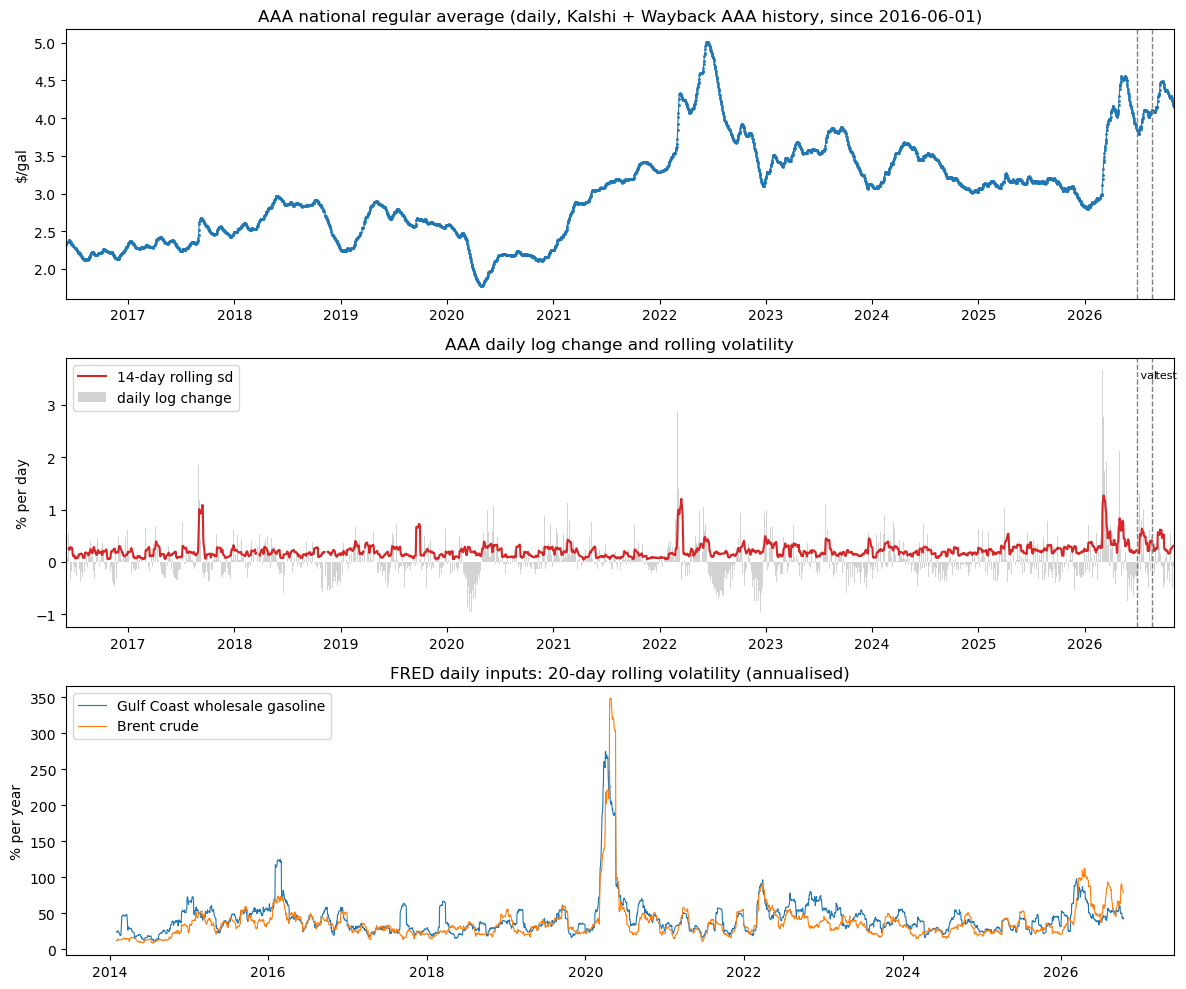

AAA daily: 3727 of 3808 days with a value, 2016-06-01 to 2026-11-03; daily-change sd 0.351% (train 0.347, val 0.462, test 0.429)


date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
sd of daily change (%),0.257,0.35,0.25,0.284,0.352,0.221,0.494,0.305,0.246,0.271,0.598
days,189.000,327.00,318.00,336.000,355.000,365.000,365.000,365.000,366.000,365.000,307.000


In [ ]:
# Daily raw data: price levels and volatility over time (AAA daily from Kalshi settlements + Wayback AAA history; FRED daily wholesale/crude)
from gaslab import data as D
_aaa = D.load_aaa_daily().asfreq("D")
_start = pd.Timestamp("2016-06-01")                                  # before this the Wayback series is sparse
_aaa = _aaa.loc[_start:]
_r_aaa = np.log(_aaa).diff() * 100                                   # daily log change, %, only where D-1 is also known
_vol_aaa = _r_aaa.rolling(14, min_periods=7).std()                   # 14-day rolling sd (the daily persistence window)
_f = D.load_fred()
_r_f = np.log(_f[["whsl_gulf", "brent"]].dropna()).diff() * 100     # business-day log changes, %
_vol_f = _r_f.rolling(20).std() * np.sqrt(252)                       # 20-day rolling sd, annualised

fig, ax = plt.subplots(3, 1, figsize=(12, 10))
ax[0].plot(_aaa.index, _aaa.values, ".-", ms=2, lw=0.8, c="C0")
ax[0].set_title(f"AAA national regular average (daily, Kalshi + Wayback AAA history, since {_start:%Y-%m-%d})"); ax[0].set_ylabel("$/gal")
ax[1].bar(_r_aaa.index, _r_aaa.values, width=1, color="lightgray", label="daily log change")
ax[1].plot(_vol_aaa.index, _vol_aaa.values, c="C3", lw=1.5, label="14-day rolling sd")
ax[1].set_title("AAA daily log change and rolling volatility"); ax[1].set_ylabel("% per day"); ax[1].legend(loc="upper left")
for a_ in ax[:2]:
    for d_, lab in [(P.D_SPLIT["train_end"], "train end"), (P.D_SPLIT["val_end"], "val end")]:
        a_.axvline(pd.Timestamp(d_), c="gray", ls="--", lw=1)
    a_.set_xlim(_aaa.index[0], _aaa.index[-1])
ax[1].text(pd.Timestamp(P.D_SPLIT["train_end"]), ax[1].get_ylim()[1] * 0.9, " val", fontsize=8)
ax[1].text(pd.Timestamp(P.D_SPLIT["val_end"]), ax[1].get_ylim()[1] * 0.9, " test", fontsize=8)
ax[2].plot(_vol_f.index, _vol_f.whsl_gulf, lw=0.8, label="Gulf Coast wholesale gasoline")
ax[2].plot(_vol_f.index, _vol_f.brent, lw=0.8, label="Brent crude")
ax[2].set_title("FRED daily inputs: 20-day rolling volatility (annualised)"); ax[2].set_ylabel("% per year"); ax[2].legend(loc="upper left")
plt.tight_layout(); plt.show()

print(f"AAA daily: {int(_aaa.notna().sum())} of {len(_aaa)} days with a value, {_start:%Y-%m-%d} to {_aaa.last_valid_index():%Y-%m-%d}; "
      f"daily-change sd {_r_aaa.std():.3f}% (train {_r_aaa.loc[:P.D_SPLIT['train_end']].std():.3f}, "
      f"val {_r_aaa.loc[P.D_SPLIT['train_end']:P.D_SPLIT['val_end']].iloc[1:].std():.3f}, test {_r_aaa.loc[P.D_SPLIT['val_end']:].iloc[1:].std():.3f})")
display(_r_aaa.groupby(_r_aaa.index.to_period("Y")).agg(["std", "count"]).rename(columns={"std": "sd of daily change (%)", "count": "days"}).round(3).T)

### 3.3 Architecture and configuration

* **Persistence**: random walk, Gaussian with rolling standard deviation (26 weeks / 14 days).
* **GARCH(1,1)-t alone**: zero-mean forecast with the GARCH(1,1)-t volatility as its scale, which shows how much of the
  deep models' gain is just the volatility model.
* **Momentum** (daily): tomorrow's change equals today's change.
* **Asymmetric ECM** (statistical baseline): OLS on lagged retail change, positive and negative wholesale changes,
  crude change and the error-correction term (retail margin minus its rolling mean).
* **Gaussian LSTM** (Stage 1 deep baseline): weekly 2 LSTM layers (32, 16 units), daily 1 layer (16 units, dense 8, L2 1e-3,
  smaller because Stage 1 had only 83 complete 7-day training windows; kept unchanged after the AAA data extension, which raised this to 3,181); **activation functions:** tanh (LSTM cell), sigmoid (gates), GELU (dense layer), linear (mean output) and softplus (scale output); orthogonal recurrent init, unit forget
  bias, dropout (0.2 weekly, 0.3 daily), L2 weight penalty (1e-4 weekly, 1e-3 daily).
  Loss: Gaussian negative log-likelihood (a strictly proper scoring rule; Gneiting & Raftery, 2007). Optimizer AdamW (weekly lr 1e-3, daily 3e-3;
  weight decay 1e-4), gradient clipping 1.0, batch 32 (weekly) / 16 (daily), up to 400/600 epochs with early stopping
  on validation NLL (patience 40/60, best weights restored). Lookback 8 weeks / 7 days. Three seeds, averaged as a mixture.
* **Student-t LSTM, no GARCH** (ablation): same network and Student-t head, no GARCH input; scale = softplus(.) + 0.05.
* **GARCH-LSTM-t** (Stage 3 extension, first version): same network plus the one-step GARCH(1,1) volatility as an
  input; Student-t head with scale = (softplus(.) + 0.05)·σ_GARCH and ν = 2.5 + softplus(.); Student-t NLL loss.
  Comparing it with the ablation shows what the GARCH input adds; comparing the ablation with the Gaussian LSTM shows
  what the heavy-tailed head adds.

The daily settings (smaller network, stronger L2, dropout 0.3, lr 3e-3, batch 16, patience 60) were set for the small
daily sample and not tuned: the daily validation window has only 50 days, so tuning on it would overfit the choice.
Daily tuning is part of the Stage 3 plan. The settings were chosen for the 83-window sample and are kept unchanged
for the extended data (3,181 windows), so the effect of the extra data is measured with the same model.

**Metric glossary.** NLL: negative log-likelihood of the realized change under the forecast distribution (changes in
percent, lower is better). CRPS: continuous ranked probability score, in percent (lower is better). MAE: absolute error of
the mean forecast, in percent. dir_acc: share of non-zero changes whose sign was predicted (blank for persistence, which
always predicts zero). cov80: share of outcomes inside the 80% interval (target 0.80). Contract accuracy: share of Kalshi
strikes where p > 0.5 matched the settled YES/NO. ATM: strikes within 1 cent of the previous AAA price, the hard ones.
Brier and log loss: probability scores on the contracts (lower is better).

Every model outputs a predictive distribution for the next log change. A Kalshi strike *k* is then priced as
P(YES) = 1 − F(100·ln(k / A<sub>D−1</sub>)), so one distribution prices the whole strike ladder consistently.

#### ▶ What the next cell does: show the two network architectures

Builds the weekly and the daily GARCH-LSTM-t with exactly the settings used later, without training them, and prints `summary()` for each:
* **weekly:** 8-week lookback over the weekly features;
* **daily:** 7-day lookback, 16 LSTM units, dropout 0.3, L2 penalty 1e-3, a dense layer of 8.

The `head="t"` output layer produces the three parameters of a Student-t distribution (mean, scale, degrees of freedom) instead of one number.

**Output:** the layers, their output shapes and the number of trainable parameters. The daily network is smaller. Its size was set when only 83 daily training windows existed and is kept unchanged now that there are 3,181 (see the data update before the Revisions).

In [5]:
# The two trained architectures (weekly and daily GARCH-LSTM-t), built with the exact settings used below
M.build_lstm(8, len(D.WEEKLY_FEATS), head="t").summary()
M.build_lstm(7, len(D.DAILY_FEATS), units=(16,), dropout=0.3, l2=1e-3, dense=8, head="t").summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 8, 8)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 8, 32)     │      5,248 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 8, 32)     │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 16)        │      3,136 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16)        │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        272 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 1)         │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 1)         │          0 │ dense_2[0][0],    │
│                     │                   │            │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 1)         │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3)         │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ lambda_1[0][0],   │
│                     │                   │            │ lambda_2[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,707 (34.01 KB)

 Trainable params: 8,707 (34.01 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 7, 7)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 16)        │      1,536 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16)        │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 8)         │        136 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │          9 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_3 (Lambda)   │ (None, 1)         │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │          9 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │          9 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_4 (Lambda)   │ (None, 1)         │          0 │ dense_6[0][0],    │
│                     │                   │            │ lambda_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_5 (Lambda)   │ (None, 1)         │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3)         │          0 │ dense_5[0][0],    │
│ (Concatenate)       │                   │            │ lambda_4[0][0],   │
│                     │                   │            │ lambda_5[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,699 (6.64 KB)

 Trainable params: 1,699 (6.64 KB)

 Non-trainable params: 0 (0.00 B)

#### ▶ What the next cell does: run the weekly Stage 1 experiment

`X.weekly_stage1()` runs the whole weekly comparison:
1. builds 10 years of weekly features from `fred.csv`: retail change, Gulf and NY Harbor wholesale changes, Brent, separate up and down wholesale moves, and the error-correction term;
2. fits GARCH(1,1)-t volatility on 2016–2022 only and adds it as a feature;
3. fits the baselines: persistence, the asymmetric ECM, and GARCH(1,1)-t alone;
4. trains three LSTMs (Gaussian, Student-t without GARCH, GARCH-LSTM-t), each with 3 seeds, and averages each one's seeds into an ensemble;
5. scores every model on validation (2023–24) and test (2025–26).

The results are stored in `s1`.

**Output:** the fitted GARCH parameters, then the comparison table: NLL, CRPS, MAE, direction accuracy, 80% coverage and number of weeks for each model and split. Lower NLL, CRPS and MAE are better; cov80 should be close to 0.80.

In [6]:
s1 = X.weekly_stage1()
print("Weekly GARCH(1,1)-t parameters (fit on 2016-2022):", s1["garch"].round(3).to_dict())
display(s1["table"].set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "MAE", "dir_acc", "cov80", "n"]])

Weekly GARCH(1,1)-t parameters (fit on 2016-2022): {'omega': 0.623, 'alpha[1]': 0.593, 'beta[1]': 0.368, 'nu': 6.913}


NLL    CRPS     MAE  dir_acc   cov80    n
split model                                                                      
test  Asymmetric ECM                 2.3364  1.0694  1.4335   0.6087  0.7717   92
      GARCH(1,1)-t alone             2.0791  1.1716  1.5899      NaN  0.8152   92
      GARCH-LSTM-t (x3)              2.0315  1.0887  1.4592   0.6196  0.7283   92
      Gaussian LSTM (x3)             2.7550  1.1680  1.5238   0.5761  0.7283   92
      Persistence                    2.7232  1.1856  1.5899      NaN  0.7609   92
      Student-t LSTM, no GARCH (x3)  2.0620  1.1140  1.4716   0.6304  0.6848   92
val   Asymmetric ECM                 1.7131  0.7317  1.0208   0.6476  0.9048  105
      GARCH(1,1)-t alone             1.7958  0.8210  1.1642      NaN  0.8571  105
      GARCH-LSTM-t (x3)              1.6972  0.7232  1.0008   0.6762  0.8190  105
      Gaussian LSTM (x3)             1.7655  0.7558  1.0558   0.6381  0.8476  105
      Persistence                    1.8008  0.8204  1.1642      NaN  0.8476  105
      Student-t LSTM, no GARCH (x3)  1.7167  0.7349  1.0320   0.6857  0.8000  105

**Reading.** On the 2025-26 test set (92 weeks) GARCH-LSTM-t has the lowest NLL (2.032) ahead of the Student-t LSTM without GARCH (2.062), the ECM (2.336), persistence (2.723) and the Gaussian LSTM (2.755). The volatility model on its own (GARCH(1,1)-t with a zero mean) reaches 2.079 on test but only 1.796 on validation, worse than every LSTM there, so the network adds more than the volatility model. The ablation separates the two changes: the Student-t head gives most of the gain (2.755 to 2.062), and the GARCH input adds a smaller one (2.062 to 2.032 on test, 1.717 to 1.697 on validation). On point accuracy the ECM is slightly better (MAE 1.434 vs 1.459, CRPS 1.069 vs 1.089), and direction accuracy is only about 0.62 for all three. The GARCH-LSTM-t's 80% interval covers 0.82 of validation weeks but only 0.73 of test weeks (ECM 0.77): its intervals were too narrow for the more volatile test period. So the deep model improves the shape of the forecast distribution, not the point forecast.

#### ▶ What the next cell does: plot the weekly learning curves

Plots training and validation NLL by epoch for the Gaussian LSTM and the GARCH-LSTM-t (seed 0).

**Output:** where the validation curve reaches its minimum (the best epoch, kept by early stopping) and whether it rises afterwards (overfitting).

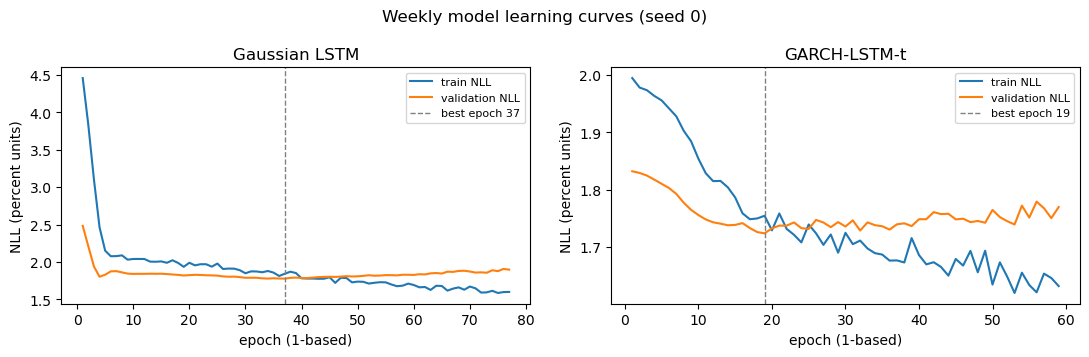

In [7]:
X.plot_learning_curves(s1["runs_g"], s1["runs_t"]); plt.show()

**Reading (learning curves).** Weekly, seed 0. The Gaussian LSTM starts far from a good fit (training NLL 4.5) and converges within about 10 epochs; its validation NLL is lowest at epoch 37. GARCH-LSTM-t starts much closer (training about 2.0, validation 1.83) because the GARCH volatility input anchors its scale, and reaches its validation minimum at epoch 19. In both, training loss keeps falling after the minimum while validation loss rises, which is overfitting that early stopping (best weights restored) removes.

#### ▶ What the next cell does: weekly convergence table

Summarises the training of all nine weekly runs (3 models × 3 seeds): epochs trained, best epoch, training and validation loss at the best and at the last epoch, and the validation-minus-training gap.

**Output:** a gap near 0 at the best epoch means no overfitting yet. A validation loss that is higher at the last epoch than at the best one means early stopping was needed.

In [8]:
conv = X.convergence_table({"Gaussian LSTM": s1["runs_g"], "Student-t LSTM, no GARCH": s1["runs_n"], "GARCH-LSTM-t": s1["runs_t"]})
display(conv.round(3))

,model,seed,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best,final_train_loss,final_val_loss,train_windows,val_minus_train_at_best
0,Gaussian LSTM,0,77,37,1.842,1.777,1.600,1.898,365,-0.065
1,Gaussian LSTM,1,93,53,1.739,1.798,1.540,1.955,365,0.059
2,Gaussian LSTM,2,69,29,1.886,1.794,1.686,1.853,365,-0.093
3,"Student-t LSTM, no GARCH",0,79,39,1.698,1.725,1.504,1.890,365,0.027
4,"Student-t LSTM, no GARCH",1,80,40,1.700,1.729,1.498,1.912,365,0.029
5,"Student-t LSTM, no GARCH",2,61,21,1.762,1.751,1.621,1.800,365,-0.010
6,GARCH-LSTM-t,0,59,19,1.754,1.724,1.632,1.770,365,-0.031
7,GARCH-LSTM-t,1,59,19,1.753,1.708,1.603,1.798,365,-0.044
8,GARCH-LSTM-t,2,93,53,1.656,1.706,1.529,1.830,365,0.049


**Reading.** In all nine weekly runs training loss keeps falling after the best epoch while validation loss rises (GARCH-LSTM-t seed 0: training 1.754 to 1.632, validation 1.724 to 1.770), so early stopping is required. At the best epoch the validation-minus-training gap is small (-0.09 to +0.06). There is no sign of underfitting: training loss can still fall well below its best-epoch value, so capacity is not the limit; generalization is. GARCH-LSTM-t reaches the lowest validation loss (1.706 to 1.724) against the Student-t LSTM without GARCH (1.725 to 1.751) and the Gaussian LSTM (1.777 to 1.798).

#### ▶ What the next cell does: run the daily Stage 1 experiment (Kalshi contracts)

`X.daily_stage(...)` builds the daily model that prices the Kalshi contracts:
1. builds daily features from the AAA daily series (Kalshi settlements plus the Wayback AAA history from June 2015); one of them is the weekly GARCH-LSTM-t forecast (`s1["res"]["GARCH-LSTM-t (x3)"].mu`), so the weekly model feeds the daily one;
2. fits the daily baselines: persistence, momentum, daily ECM, and GARCH alone;
3. trains the three LSTM types with a 7-day lookback, 3 seeds each;
4. turns every forecast distribution into P(YES) for each Kalshi strike and scores it against the settled outcome;
5. adds the Kalshi market price 1 hour after the open as a benchmark.

The results are stored in `ds`.

**Output:** the table with distribution scores (NLL, CRPS, dir_acc) and contract scores (accuracy, ATM accuracy, Brier, log loss, number of contracts and events), then the number of labelled days before July 2026 (3,599) and of complete 7-day training windows (3,181). The test window is Aug 20 – Oct 19 2026 (61 settlement days).

In [9]:
ds = X.daily_stage(s1["res"]["GARCH-LSTM-t (x3)"].mu, lookbacks=(7,), heads=("gauss", "t_nog", "t"))
cols = ["NLL", "CRPS", "dir_acc", "accuracy", "atm_accuracy", "brier", "logloss", "contracts", "events"]
display(ds["table"].set_index(["split", "model"]).sort_index()[cols])
print("Daily labelled days up to 2026-06-30:", int(ds["df"].y.loc[:"2026-06-30"].notna().sum()),
      "| complete 7-day LSTM training windows:", int(ds["runs"][7]["t"][0]["masks"][0].sum()))

NLL    CRPS  dir_acc  accuracy  atm_accuracy   brier  logloss  contracts  events
split model                                                                                                                      
test  Daily ECM                               0.5927  0.1475   0.7541    0.9097        0.8219  0.0712   0.2950       1107      61
      GARCH(1,1)-t alone                      0.2667  0.2001      NaN    0.8726        0.6923  0.0946   0.3523       1107      61
      GARCH-LSTM-t lb7 (x3)                  -0.1198  0.1315   0.8361    0.9160        0.8057  0.0631   0.2570       1107      61
      Gaussian LSTM lb7 (x3)                  0.6992  0.1311   0.8033    0.9151        0.8097  0.0636   0.2596       1107      61
      Kalshi market (9 a.m., 1 h after open)     NaN     NaN      NaN    0.9330        0.8502  0.0489   0.1639       1105      61
      Momentum                                0.4932  0.1784   0.7213    0.8880        0.7773  0.0859   0.3184       1107      61
      Persistence                             0.7089  0.2138      NaN    0.8726        0.6923  0.1023   0.3895       1107      61
      Student-t LSTM, no GARCH lb7 (x3)      -0.1732  0.1263   0.8033    0.9187        0.8097  0.0611   0.2405       1107      61
val   Daily ECM                               0.5981  0.1686   0.7708    0.8981        0.8000  0.0745   0.2911        913      50
      GARCH(1,1)-t alone                      0.5686  0.2454      NaN    0.8510        0.6350  0.1061   0.3656        913      50
      GARCH-LSTM-t lb7 (x3)                  -0.1510  0.1414   0.8125    0.9135        0.8200  0.0632   0.2181        913      50
      Gaussian LSTM lb7 (x3)                  0.2614  0.1411   0.8125    0.9168        0.8250  0.0628   0.2502        913      50
      Kalshi market (9 a.m., 1 h after open)     NaN     NaN      NaN    0.9262        0.8571  0.0527   0.1654        122       7
      Momentum                                0.6954  0.2088   0.7708    0.8828        0.7950  0.0904   0.3264        913      50
      Persistence                             1.0922  0.2558      NaN    0.8510        0.6350  0.1133   0.4163        913      50
      Student-t LSTM, no GARCH lb7 (x3)      -0.1692  0.1332   0.8333    0.9168        0.8200  0.0597   0.2179        913      50

Daily labelled days up to 2026-06-30: 3599 | complete 7-day LSTM training windows: 3181


**Reading.** The daily test covers 61 settlement days (Aug 20 – Oct 19 2026, 1,107 listed strikes). With the Wayback AAA history the LSTMs are trained on 3,181 complete 7-day windows (2015 to June 2026) instead of 83. Persistence and momentum are not trained and score exactly as in the 83-window version (test NLL 0.709 and 0.493), so the test targets are unchanged and the comparison is like for like.

* **Best models.** The two Student-t LSTMs are clearly the best forecasters. Test NLL is −0.173 without GARCH and −0.120 for GARCH-LSTM-t. The other models score 0.267 (GARCH alone), 0.493 (momentum), 0.593 (ECM) and 0.699 (Gaussian LSTM).
* **The GARCH input no longer helps.** With 83 windows, it was the GARCH input that made GARCH-LSTM-t best. With 3,181 windows, the Student-t LSTM without it is slightly better on test (NLL −0.173 vs −0.120, CRPS 0.126 vs 0.132, Brier 0.061 vs 0.063) and on validation (−0.169 vs −0.151).
* **The heavy-tailed head matters, through NLL only.** The Gaussian LSTM has the same CRPS (0.131) and Brier (0.064) as GARCH-LSTM-t, so its mean forecast is as good. Its high NLL comes from a few large moves that its thin tails rate as almost impossible.
* **The deep models now beat momentum on point accuracy.** CRPS is 0.126–0.132 against 0.178, and ATM accuracy 0.806–0.810 against 0.777. With 83 windows, momentum had the best CRPS.
* **The market is still better.** The Kalshi price one hour after the open beats every model (accuracy 0.933, ATM 0.850, Brier 0.049 vs 0.061–0.063). Section 5 tests whether that gap is significant. On validation the market benchmark covers only 7 events (122 of 913 contracts), because the order-book history starts in August, so it is not comparable there.

#### ▶ What the next cell does: daily learning curves and convergence table

Same as the two weekly cells above, but for the daily models: the learning curves of the Gaussian LSTM and the GARCH-LSTM-t (seed 0), then the convergence table of all nine daily runs.

**Output:** how early the validation minimum comes and how fast validation loss climbs afterwards. With 3,181 training windows the networks train longer before the validation minimum than they did with 83, but validation loss still rises afterwards.

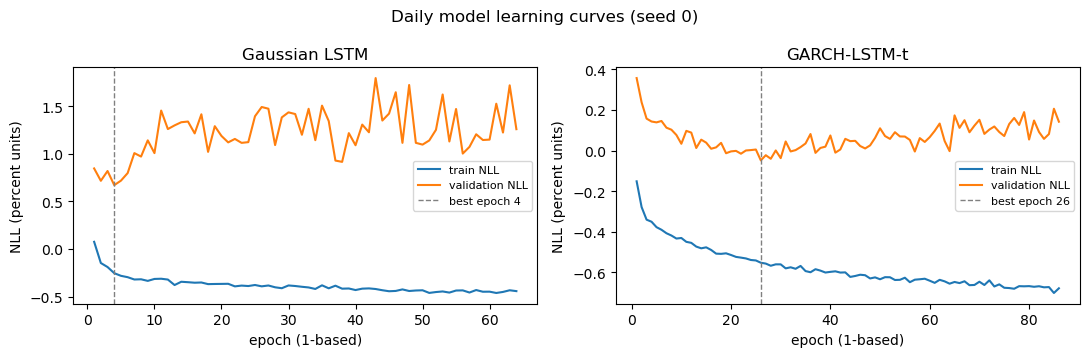

,model,seed,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best,final_train_loss,final_val_loss,train_windows,val_minus_train_at_best
0,Gaussian LSTM (daily),0,64,4,-0.254,0.672,-0.443,1.261,3181,0.926
1,Gaussian LSTM (daily),1,99,39,-0.421,0.380,-0.490,1.525,3181,0.801
2,Gaussian LSTM (daily),2,66,6,-0.313,0.319,-0.461,1.877,3181,0.632
3,"Student-t, no GARCH (daily)",0,68,8,-0.435,0.074,-0.666,0.653,3181,0.508
4,"Student-t, no GARCH (daily)",1,89,29,-0.512,-0.046,-0.682,0.353,3181,0.466
5,"Student-t, no GARCH (daily)",2,109,49,-0.591,-0.212,-0.699,0.005,3181,0.378
6,GARCH-LSTM-t (daily),0,86,26,-0.553,-0.048,-0.679,0.143,3181,0.504
7,GARCH-LSTM-t (daily),1,76,16,-0.481,-0.076,-0.673,0.243,3181,0.405
8,GARCH-LSTM-t (daily),2,75,15,-0.503,-0.107,-0.693,0.197,3181,0.396


In [10]:
X.plot_learning_curves(ds["runs"][7]["gauss"], ds["runs"][7]["t"], title="Daily model learning curves (seed 0)"); plt.show()
display(X.convergence_table({"Gaussian LSTM (daily)": ds["runs"][7]["gauss"], "Student-t, no GARCH (daily)": ds["runs"][7]["t_nog"],
                             "GARCH-LSTM-t (daily)": ds["runs"][7]["t"]}).round(3))

**Reading.** With 3,181 training windows the daily curves are much healthier than with 83.
* **Later, better minimum.** GARCH-LSTM-t reaches its validation minimum at epochs 15–26 (with 83 windows, as early as epoch 2). Its validation NLL at the best epoch is −0.107 to −0.048, against 0.37–0.68 before.
* **Still overfits after the minimum.** Validation loss rises afterwards, to 0.14–0.24 for GARCH-LSTM-t at the last epoch and up to 1.88 for the Gaussian LSTM, so early stopping is still needed.
* **Large train/validation gap.** At the best epoch, validation NLL is 0.38 to 0.93 above training NLL. Training NLL averages over 2015–2026, while validation covers only July–August 2026, so the gap mixes overfitting with a validation period that is harder than average.

The data limit identified in Stage 1 is largely removed. What remains is the overfitting after the minimum and the interval calibration (Revision 3 shows the daily 80% intervals are now too narrow).

## Revisions (Part 2)

The five revisions below build on the Stage 1 results above.

**Data update (2026-11-04).** The daily AAA series was extended from 367 Kalshi settlement values (Sep 2023 – Oct 2026)
to 3,865 days (Jun 2015 – Nov 2026), using Wayback Machine snapshots of gasprices.aaa.com (`data/manual_aaa.csv`).
* **Coverage.** From June 2016 on, 3,727 of 3,808 days have a value (97.9%), and no gap is longer than 2 days. Before June 2016 there are 138 sparse days.
* **Sources.** 3,422 values were read directly from the page. The rest come from the page's week-, month- or year-ago row, which match the directly read values on 99.5%, 98.7% and 87% of overlapping days. `data/manual_aaa_sources.csv` records each value's source.
* **Check against Kalshi.** On days both sources have, the values are identical after aligning on AAA's own "Price as of" date. That check also showed that the Kalshi settlement dates for Sep 2023 – Apr 2024 are shifted by one day; the Wayback values, which take precedence in `load_aaa_daily()`, correct this.
* **Effect.** Daily LSTM training windows grew from 83 to 3,181. All daily numbers in this notebook use the extended data. Weekly results are unchanged, because the weekly model uses EIA data.

**Code change.** The only change to `gaslab/` is that the daily test window now has a fixed end: `X.TE` = Aug 20 – Oct 19 2026,
the last settled Kalshi contract. Newer AAA days therefore do not enter the test set. `results/part2.pkl`, which holds the weekly
frame and forecasts, is saved in the last cell as before. Every new number is computed on the same splits: weekly
validation 2023–2024 and test 2025–26; daily validation Jul 1 – Aug 19 2026 and test Aug 20 – Oct 19 2026. Choices are made on validation data only, and test numbers are reported only after the choice.

| # | Revision | Question it answers |
|---|---|---|
| 1 | Scale calibration of the predictive distributions | Can the too-narrow test intervals (80% coverage 0.73) be fixed without look-ahead? |
| 2 | New baseline: ECM mean + GARCH(1,1)-t on its residuals | Does the LSTM beat a simple statistical model that also has time-varying volatility? |
| 3 | Exact seed-mixture scoring | Does the moment-matched ensemble understate what the 3-seed mixture actually achieves? |
| 4 | Diebold–Mariano tests (with Holm correction) | Are the NLL/CRPS differences in the Stage 1 tables statistically significant? |
| 5 | Daily model: 5 seeds and stronger regularization | Do more seeds or stronger regularization still help once the daily model has 3,181 training windows? |

The next cell defines the helper functions used by all five revisions.

#### ▶ What the next cell does: define the helper functions for Revisions 1–5

Defines the tools the five revisions use; nothing is trained or scored yet. It also sets the split ranges (`WRNG` weekly, `DRNG` daily), short names for the data (`wk`, `dly`, `dcon`) and `REV`, a dictionary that collects the revision tables.
* **Revision 1:** `fit_scale_factor`, `static_calibrate`, `rolling_calibrate` (scale calibration) and `coverage_table` (coverage at 50/80/90/95%).
* **Revision 2:** `ecm_garch_t` (ECM mean + GARCH(1,1)-t fitted on the ECM residuals).
* **Revision 3:** `comps_on`, `mix_logpdf`, `mix_cdf`, `mix_crps`, `mix_metrics`, `price_ladder_mix` (scoring the exact mixture of the seeds).
* **Revision 4:** `dm_test` (Diebold–Mariano test), `holm` (multiple-testing correction), `obs_losses` and `dm_table`.
* **Revision 5:** `run_daily_cfg` (one daily training run with adjustable settings).

**Output:** only the line `revision helpers ready`.

In [11]:
# ===================== Revision helpers (used by Revisions 1-5) =====================
from scipy import stats, optimize
from scipy.special import logsumexp
from arch import arch_model

WRNG = {"val": X.WVA, "test": X.WTE}          # weekly splits (same as the Stage 1 table)
DRNG = {"val": X.VA, "test": X.TE}            # daily splits
wk, dly, dcon = s1["w"], ds["df"], ds["contracts"]
REV = {}                                      # collects the revision tables (saved at the end)


def on(d, rng):
    return d.loc[rng[0]:rng[1]].dropna()


def coverage_table(res, y_series, rngs, levels=(0.5, 0.8, 0.9, 0.95)):
    # central-interval coverage at several nominal levels, from the PIT value F(y)
    rows = []
    for name, d in res.items():
        for lab, r in rngs.items():
            dd = on(d, r); y = y_series.loc[dd.index].values * 100
            u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)
            rows.append({"model": name, "split": lab, "n": len(y),
                         **{f"cov{int(l * 100)} (nominal {l:.2f})": float(np.mean(np.abs(u - 0.5) <= l / 2)) for l in levels}})
    return pd.DataFrame(rows)


# ---------- Revision 1: scale calibration ----------
def fit_scale_factor(y, d, bounds=(0.3, 5.0)):
    # k that minimises the mean NLL of y under the distribution with scale multiplied by k
    mu, sc, nu = d.mu.values, d.scale.values, d.df.values
    f = lambda lk: -np.mean(E.logpdf(y, mu, sc * np.exp(lk), nu))
    return float(np.exp(optimize.minimize_scalar(f, bounds=np.log(bounds), method="bounded").x))


def static_calibrate(d, y_series, fit_rng):
    dd = on(d, fit_rng)
    k = fit_scale_factor(y_series.loc[dd.index].values * 100, dd)
    out = d.copy(); out["scale"] = d.scale * k
    return out, k


def rolling_calibrate(d, y_series, oos_start, window=52, min_obs=13):
    # k_t is fitted on the out-of-sample outcomes BEFORE origin t only (rows after oos_start, at most `window`
    # of them). Row t-1's outcome is known at origin t (weekly: Monday t's EIA price is the outcome of week t-1).
    # Until min_obs out-of-sample outcomes exist, k = 1 (no calibration).
    d = d.dropna(); idx = d.index; yv = y_series.reindex(idx).values * 100
    oos = idx > pd.Timestamp(oos_start)
    k = np.ones(len(d))
    for i in range(len(d)):
        if not oos[i]: continue
        past = np.where(oos[:i] & ~np.isnan(yv[:i]))[0][-window:]
        if len(past) >= min_obs:
            k[i] = fit_scale_factor(yv[past], d.iloc[past])
    out = d.copy(); out["scale"] = d.scale.values * k
    return out, pd.Series(k, index=idx)


# ---------- Revision 2: ECM mean + GARCH(1,1)-t on the ECM residuals ----------
def ecm_garch_t(frame, feats, split, train_start=None):
    ok = frame.dropna(subset=["y"] + feats)
    tr, _, _ = P.split_masks(ok.index, split, train_start)
    ecm, _ = M.ecm_fit_predict(ok, feats, tr)
    e = ok["y"].values * 100 - ecm.mu.values                       # residual of row i is known at origin i+1
    fit = arch_model(e[tr], mean="Zero", vol="GARCH", p=1, q=1, dist="t", rescale=False).fit(disp="off")
    om, al, be, nu = (float(fit.params[k]) for k in ["omega", "alpha[1]", "beta[1]", "nu"])
    s2 = np.empty(len(e)); s2[0] = e[tr].var()
    for i in range(1, len(e)):
        s2[i] = om + al * e[i - 1] ** 2 + be * s2[i - 1]          # sigma^2 for row i uses residuals up to i-1
    out = pd.DataFrame({"mu": ecm.mu.values, "scale": np.sqrt(s2 * (nu - 2) / nu), "df": nu}, index=ok.index)
    return out, pd.Series(dict(omega=om, alpha=al, beta=be, nu=nu, train_obs=int(tr.sum())))


# ---------- Revision 3: exact mixture of the seed distributions ----------
def comps_on(runs, rng):
    parts = [r["dist"].loc[rng[0]:rng[1]].dropna() for r in runs]
    common = parts[0].index
    for p in parts[1:]: common = common.intersection(p.index)
    return [p.loc[common] for p in parts]


def mix_logpdf(y, comps):
    lp = np.stack([E.logpdf(y, c.mu.values, c.scale.values, c.df.values) for c in comps])
    return logsumexp(lp, axis=0) - np.log(len(comps))


def mix_cdf(x, comps):
    return np.mean([E.cdf(x, c.mu.values, c.scale.values, c.df.values) for c in comps], axis=0)


def mix_crps(y, comps, n=2000, seed=0):
    # Monte Carlo CRPS of the equal-weight mixture (same estimator as evaluate.crps_mc)
    rng = np.random.default_rng(seed); K, N = len(comps), len(y)
    mu = np.stack([c.mu.values for c in comps]); sc = np.stack([c.scale.values for c in comps])
    nu = np.stack([c.df.values for c in comps])
    k = rng.integers(0, K, size=(n, N)); col = np.arange(N)
    m, s, v = mu[k, col], sc[k, col], nu[k, col]
    z = np.where(np.isinf(v), rng.standard_normal((n, N)), rng.standard_t(np.where(np.isinf(v), 30, v)))
    x = m + s * z; x2 = np.roll(x, 1, axis=0)
    return np.mean(np.abs(x - y), 0) - 0.5 * np.mean(np.abs(x - x2), 0)


def mix_metrics(y, comps):
    mu = np.mean([c.mu.values for c in comps], axis=0); nz = y != 0
    u = mix_cdf(y, comps)
    return {"NLL": float(-mix_logpdf(y, comps).mean()), "CRPS": float(mix_crps(y, comps).mean()),
            "MAE": float(np.abs(y - mu).mean()), "dir_acc": float((np.sign(mu[nz]) == np.sign(y[nz])).mean()),
            "cov80": float(np.mean(np.abs(u - 0.5) <= 0.4)), "n": int(len(y))}


def price_ladder_mix(contracts, comps):
    c = contracts[contracts.date.isin(comps[0].index)].copy()
    x = 100 * np.log(c.strike.values / c.prev.values)
    p = np.mean([1 - E.cdf(x, d.mu.reindex(c.date).values, d.scale.reindex(c.date).values,
                           d.df.reindex(c.date).values) for d in comps], axis=0)
    c["p"] = np.clip(p, 1e-4, 1 - 1e-4)
    return c


# ---------- Revision 4: Diebold-Mariano test ----------
def dm_test(loss_a, loss_b, h=1, lag=None):
    # H0: equal expected loss. d = loss_a - loss_b (negative mean -> A better). Newey-West (Bartlett) long-run
    # variance with lag floor(T^(1/3)), Harvey-Leybourne-Newbold small-sample correction, t(T-1) reference.
    d = np.asarray(loss_a, float) - np.asarray(loss_b, float); d = d[np.isfinite(d)]; T = len(d)
    lag = int(np.floor(T ** (1 / 3))) if lag is None else lag
    dc = d - d.mean()
    lrv = dc @ dc / T + 2 * sum((1 - j / (lag + 1)) * (dc[j:] @ dc[:-j]) / T for j in range(1, lag + 1))
    dm = d.mean() / np.sqrt(lrv / T)
    dm *= np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return dict(mean_diff=float(d.mean()), DM=float(dm), p_value=float(2 * stats.t.sf(abs(dm), T - 1)), n=T)


def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj


def obs_losses(d, y_series, idx):
    dd = d.loc[idx]; y = y_series.loc[idx].values * 100
    return {"NLL": -E.logpdf(y, dd.mu.values, dd.scale.values, dd.df.values),
            "CRPS": E.crps_mc(y, dd.mu.values, dd.scale.values, dd.df.values)}   # same seed -> common random numbers


def dm_table(res, ref, others, y_series, rngs, contracts=None):
    rows = []
    for lab, r in rngs.items():
        idx = on(res[ref], r).index
        for o in others: idx = idx.intersection(on(res[o], r).index)
        idx = idx[y_series.loc[idx].notna().values]
        la = obs_losses(res[ref], y_series, idx)
        if contracts is not None:
            ca = E.price_ladder(contracts[contracts.date.isin(idx)], res[ref].loc[idx])
            la["Brier (per day)"] = ((ca.p - ca.y) ** 2).groupby(ca.date).mean().reindex(idx).values
        for o in others:
            lb = obs_losses(res[o], y_series, idx)
            if contracts is not None:
                cb = E.price_ladder(contracts[contracts.date.isin(idx)], res[o].loc[idx])
                lb["Brier (per day)"] = ((cb.p - cb.y) ** 2).groupby(cb.date).mean().reindex(idx).values
            for metric in la:
                rows.append({"split": lab, "metric": metric, "model A": ref, "model B": o, **dm_test(la[metric], lb[metric])})
    t = pd.DataFrame(rows)
    t["p_holm"] = t.groupby(["split", "metric"]).p_value.transform(lambda p: holm(p.values))
    t["verdict"] = np.where(t.p_holm < 0.05, np.where(t.mean_diff < 0, "A better", "B better"), "no significant difference")
    return t


# ---------- Revision 5: daily runs with configurable training settings ----------
def run_daily_cfg(df, seed, lookback=7, units=(16,), dense=8, dropout=0.3, l2=1e-3, lr=3e-3, batch=16,
                  patience=60, epochs=600, head="t"):
    # same as pipeline.run_daily, but patience, batch size and dense width are arguments
    feats = D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"]
    Xs, ys, idx = D.sequences(df, feats, lookback)
    tr, va, te = P.split_masks(idx, P.D_SPLIT)
    tr &= ~np.isnan(ys); va &= ~np.isnan(ys)
    sc = M.Scaler(keep_last_raw=head == "t").fit(Xs[tr])
    m, hist = M.train_lstm(sc(Xs[tr]), ys[tr], sc(Xs[va]), ys[va], head=head, lr=lr, seed=seed, epochs=epochs,
                           units=units, dropout=dropout, l2=l2, dense=dense, batch=batch, patience=patience)
    d = M.predict_dist(m, sc(Xs), head); d.index = idx
    return dict(hist=hist, dist=d, idx=idx, y=ys, masks=(tr, va, te))

print("revision helpers ready")

revision helpers ready


## Revision 1: Scale calibration of the weekly predictive distributions

**What I changed.** I added two post-hoc calibrations of the predictive scale, applied to the weekly Gaussian LSTM,
Student-t LSTM (no GARCH), GARCH-LSTM-t and ECM. Each multiplies the model's scale by a factor *k*, with the mean and
tail parameter left unchanged.
* **Static:** a single *k* chosen to minimise NLL on the 2023–24 validation weeks, then applied unchanged to the test.
* **Rolling:** at each forecast origin *t*, *k* is refitted on the out-of-sample outcomes observed before *t* (at most
  52 weeks, all after the training period). Until 13 such weeks exist, *k* = 1. It uses no future data, so it could
  run live.

I also report coverage at 50/80/90/95% instead of 80% only.

**Why.** The Stage 1 reading shows GARCH-LSTM-t's 80% interval covering 0.82 of validation weeks but only 0.73 of
test weeks: the intervals were too narrow for the more volatile 2025–26 period. For a Kalshi strike ladder, a
too-narrow distribution means overconfident YES/NO probabilities, which is exactly where losses come from.

**Result.** Calibration does not fix GARCH-LSTM-t.

The static factors fitted on 2023–24 validation are close to 1 for the deep models: GARCH-LSTM-t k = 0.974, Gaussian LSTM 0.942, Student-t LSTM 0.979 (ECM 0.798). On validation these models were already well calibrated (GARCH-LSTM-t cov80 0.82), so validation gives no signal to widen the intervals.

On test, GARCH-LSTM-t's NLL moves from 2.032 to 2.037 (static) and 2.035 (rolling), and cov80 stays at 0.72–0.73, even though the rolling k ranged from 0.85 to 1.31 during the test period. The coverage table shows why: GARCH-LSTM-t covers only 0.42 at the 50% level but 0.935 at 95%. Its centre is too narrow while its tails are about right. That is a shape problem, and one scale factor cannot correct it.

Rolling calibration does help the models whose scale is less well specified:
* Gaussian LSTM: test NLL 2.755 → 2.487, cov80 0.73 → 0.78.
* Student-t LSTM without GARCH: test NLL 2.062 → 2.046, cov80 0.68 → 0.72.
* ECM: the static factor backfires (test NLL 2.336 → 2.648, cov80 0.68), because it shrinks the intervals to fit the calmer validation years, the opposite of what the volatile test period needed. Rolling k gives the ECM near-nominal coverage (0.80) and a lower CRPS (1.069 → 1.053), but a higher NLL (2.512).

Two caveats:
1. The idea for this revision came from the Stage 1 *test* coverage, so it is not a clean out-of-sample discovery. No parameter was fitted on test, but the test comparisons above should be read with that in mind.
2. With 92 test weeks, a perfectly calibrated model would show cov80 between 0.72 and 0.88 in 95% of samples (binomial). Observing 67 of 92 weeks inside the interval gives a two-sided p of about 0.12. The original "intervals were too narrow" finding is itself only weak evidence.

#### ▶ What the next cell does: run Revision 1 (scale calibration)

For four weekly models, it builds two calibrated versions: one with the static factor *k* fitted on validation, one with a rolling *k* re-fitted each week on past out-of-sample outcomes. It then scores the original and both versions on validation and test, builds the coverage table at four levels for test, and draws two plots.

**Output:** the static *k* values; the table of NLL, CRPS and cov80; the coverage table; a plot of the rolling *k* over time; and a plot of test coverage against nominal coverage (on the dashed diagonal = perfectly calibrated). The last line, `RESULT: …`, summarises the numbers used in the Result text above.

Static scale factors fitted on 2023-24 validation: {'Gaussian LSTM (x3)': 0.942, 'Student-t LSTM, no GARCH (x3)': 0.979, 'GARCH-LSTM-t (x3)': 0.974, 'Asymmetric ECM': 0.798}


NLL    CRPS   cov80    n
split model                                                                 
test  Asymmetric ECM                             2.3364  1.0694  0.7717   92
      Asymmetric ECM + rolling k                 2.5123  1.0532  0.8043   92
      Asymmetric ECM + static k                  2.6478  1.0819  0.6848   92
      GARCH-LSTM-t (x3)                          2.0315  1.0887  0.7283   92
      GARCH-LSTM-t (x3) + rolling k              2.0346  1.0903  0.7283   92
      GARCH-LSTM-t (x3) + static k               2.0372  1.0897  0.7174   92
      Gaussian LSTM (x3)                         2.7550  1.1680  0.7283   92
      Gaussian LSTM (x3) + rolling k             2.4873  1.1582  0.7826   92
      Gaussian LSTM (x3) + static k              2.8881  1.1715  0.7065   92
      Student-t LSTM, no GARCH (x3)              2.0620  1.1140  0.6848   92
      Student-t LSTM, no GARCH (x3) + rolling k  2.0462  1.1073  0.7174   92
      Student-t LSTM, no GARCH (x3) + static k   2.0684  1.1157  0.6739   92
val   Asymmetric ECM                             1.7131  0.7317  0.9048  105
      Asymmetric ECM + rolling k                 1.6761  0.7221  0.8571  105
      Asymmetric ECM + static k                  1.6691  0.7212  0.8000  105
      GARCH-LSTM-t (x3)                          1.6972  0.7232  0.8190  105
      GARCH-LSTM-t (x3) + rolling k              1.7022  0.7265  0.8000  105
      GARCH-LSTM-t (x3) + static k               1.6968  0.7227  0.7810  105
      Gaussian LSTM (x3)                         1.7655  0.7558  0.8476  105
      Gaussian LSTM (x3) + rolling k             1.7598  0.7562  0.8476  105
      Gaussian LSTM (x3) + static k              1.7621  0.7527  0.8286  105
      Student-t LSTM, no GARCH (x3)              1.7167  0.7349  0.8000  105
      Student-t LSTM, no GARCH (x3) + rolling k  1.7209  0.7368  0.8095  105
      Student-t LSTM, no GARCH (x3) + static k   1.7164  0.7348  0.8000  105

n  cov50 (nominal 0.50)  cov80 (nominal 0.80)  cov90 (nominal 0.90)  cov95 (nominal 0.95)
split model                                                                                                                                
test  Gaussian LSTM (x3)                         92                 0.500                 0.728                 0.815                 0.870
      Gaussian LSTM (x3) + static k              92                 0.489                 0.707                 0.772                 0.859
      Gaussian LSTM (x3) + rolling k             92                 0.533                 0.783                 0.837                 0.902
      Student-t LSTM, no GARCH (x3)              92                 0.424                 0.685                 0.837                 0.924
      Student-t LSTM, no GARCH (x3) + static k   92                 0.413                 0.674                 0.837                 0.913
      Student-t LSTM, no GARCH (x3) + rolling k  92                 0.402                 0.717                 0.870                 0.924
      GARCH-LSTM-t (x3)                          92                 0.424                 0.728                 0.859                 0.935
      GARCH-LSTM-t (x3) + static k               92                 0.413                 0.717                 0.848                 0.935
      GARCH-LSTM-t (x3) + rolling k              92                 0.413                 0.728                 0.859                 0.946
      Asymmetric ECM                             92                 0.500                 0.772                 0.859                 0.946
      Asymmetric ECM + static k                  92                 0.424                 0.685                 0.783                 0.837
      Asymmetric ECM + rolling k                 92                 0.457                 0.804                 0.891                 0.935

Note: the static rows are in-sample on validation (k was fitted there); compare them on test.


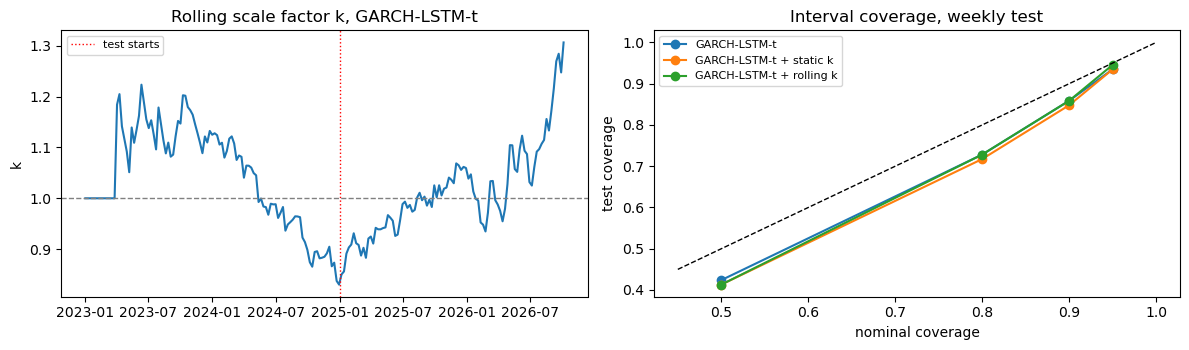

RESULT: GARCH-LSTM-t (x3) test NLL 2.032 -> static 2.037 (k=0.974) -> rolling 2.035; test cov80 0.73 -> 0.72 -> 0.73; rolling k on test ranged 0.85-1.31


In [12]:
cal_models = ["Gaussian LSTM (x3)", "Student-t LSTM, no GARCH (x3)", "GARCH-LSTM-t (x3)", "Asymmetric ECM"]
res_cal, k_static, k_roll = {}, {}, {}
for name in cal_models:
    d = s1["res"][name]
    d_st, k_static[name] = static_calibrate(d, wk["y"], X.WVA)
    d_ro, k_roll[name] = rolling_calibrate(d, wk["y"], oos_start=P.W_SPLIT["train_end"])
    res_cal[name] = d
    res_cal[name + " + static k"] = d_st
    res_cal[name + " + rolling k"] = d_ro

print("Static scale factors fitted on 2023-24 validation:", {k: round(v, 3) for k, v in k_static.items()})
cal_tab = X._rows(res_cal, wk["y"], WRNG)[["split", "model", "NLL", "CRPS", "cov80", "n"]]
display(cal_tab.set_index(["split", "model"]).sort_index().round(4))
cov_tab = coverage_table(res_cal, wk["y"], {"test": X.WTE})
display(cov_tab.set_index(["split", "model"]).round(3))
REV["r1_calibration"], REV["r1_coverage"] = cal_tab, cov_tab
print("Note: the static rows are in-sample on validation (k was fitted there); compare them on test.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
kr = k_roll["GARCH-LSTM-t (x3)"].loc[X.WVA[0]:]
ax[0].plot(kr.index, kr.values); ax[0].axhline(1, c="gray", ls="--", lw=1)
ax[0].axvline(pd.Timestamp(X.WTE[0]), c="r", ls=":", lw=1, label="test starts")
ax[0].set_title("Rolling scale factor k, GARCH-LSTM-t"); ax[0].set_ylabel("k"); ax[0].legend(fontsize=8)
lev = [0.5, 0.8, 0.9, 0.95]
for nm in ["GARCH-LSTM-t (x3)", "GARCH-LSTM-t (x3) + static k", "GARCH-LSTM-t (x3) + rolling k"]:
    row = cov_tab[cov_tab.model == nm].iloc[0]
    ax[1].plot(lev, [row[f"cov{int(l * 100)} (nominal {l:.2f})"] for l in lev], "o-", label=nm.replace("GARCH-LSTM-t (x3)", "GARCH-LSTM-t"))
ax[1].plot([0.45, 1], [0.45, 1], "k--", lw=1); ax[1].set_xlabel("nominal coverage"); ax[1].set_ylabel("test coverage")
ax[1].set_title("Interval coverage, weekly test"); ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

t = cal_tab[cal_tab.split == "test"].set_index("model")
g = "GARCH-LSTM-t (x3)"
print(f"RESULT: {g} test NLL {t.loc[g, 'NLL']:.3f} -> static {t.loc[g + ' + static k', 'NLL']:.3f} "
      f"(k={k_static[g]:.3f}) -> rolling {t.loc[g + ' + rolling k', 'NLL']:.3f}; test cov80 {t.loc[g, 'cov80']:.2f} -> "
      f"{t.loc[g + ' + static k', 'cov80']:.2f} -> {t.loc[g + ' + rolling k', 'cov80']:.2f}; "
      f"rolling k on test ranged {kr.loc[X.WTE[0]:].min():.2f}-{kr.loc[X.WTE[0]:].max():.2f}")

## Revision 2: New statistical baseline: ECM mean + GARCH(1,1)-t on the ECM residuals

**What I changed.** I added an **ECM-GARCH-t** baseline, weekly and daily. The mean is the same asymmetric ECM
(OLS on the training split). The scale comes from a GARCH(1,1) with Student-t errors, fitted to the ECM's
**training residuals** and then run forward with fixed parameters. The variance for row *t* uses residuals up to
*t−1* only, so there is no look-ahead. I report it on the same metrics as Stage 1, including the Kalshi contract
metrics for the daily version.

**Why.** Stage 1 compares GARCH-LSTM-t against an ECM with a *constant* scale and a GARCH model with a *zero* mean.
Neither has both a good mean and time-varying volatility. That leaves open whether the LSTM's NLL advantage comes
from the network or just from combining those two pieces. This baseline is the strongest simple econometric
competitor, so beating it is the fair test of the deep model.

**Result.** On the weekly data, this simple model is the best forecaster in the table.

ECM-GARCH-t has the lowest NLL on both splits: validation 1.689 (GARCH-LSTM-t 1.697, ECM 1.713) and test 1.999 (GARCH-LSTM-t 2.032, ECM 2.336). It also has the lowest CRPS on both: validation 0.722 vs 0.723, test 1.054 vs 1.089. Its 80% coverage is 0.80 on validation and 0.77 on test, against 0.82 and 0.73 for GARCH-LSTM-t. Because it uses the ECM's mean, its MAE (1.434 on test) and direction accuracy (0.61) are the same as the ECM's. The fitted GARCH is persistent (α = 0.085, β = 0.812, ν = 5.0).

Adding GARCH volatility to the ECM therefore closes, and slightly reverses, the gap to the LSTM. On weekly data, the deep model's advantage over the constant-scale ECM comes from time-varying volatility, not from the network.

On the daily data the picture is different. ECM-GARCH-t is a large improvement over the daily ECM: test NLL 0.043 vs 0.593, validation 0.223 vs 0.598. Its GARCH is now fitted on 3,435 residuals instead of 92. Because it keeps the ECM mean, its CRPS and Brier are almost the same as the ECM's (test Brier 0.0711 vs 0.0712).

GARCH-LSTM-t stays ahead on both splits: validation NLL −0.151, test −0.120, with test Brier 0.0631 vs 0.0711 and CRPS 0.132 vs 0.149. Unlike on weekly data, the daily network improves the mean forecast as well as the scale. Revision 4 tests whether these gaps are significant.

#### ▶ What the next cell does: run Revision 2 (ECM-GARCH-t baseline)

Fits the new ECM-GARCH-t model on the weekly and the daily data and prints its GARCH parameters. It then compares it with persistence, the ECM, GARCH alone and GARCH-LSTM-t, weekly and daily (the daily table includes the Kalshi contract scores).

**Output:** the parameter table (omega, alpha, beta, nu, number of training residuals), the weekly and daily comparison tables, and two `RESULT:` lines with the key NLL numbers.

In [13]:
eg_w, eg_w_par = ecm_garch_t(wk, P.ECM_W, P.W_SPLIT, P.W_SPLIT["train_start"])
eg_d, eg_d_par = ecm_garch_t(dly, P.ECM_D, P.D_SPLIT)
display(pd.DataFrame({"weekly": eg_w_par, "daily": eg_d_par}).round(4))

res_w2 = {k: s1["res"][k] for k in ["Persistence", "Asymmetric ECM", "GARCH(1,1)-t alone", "GARCH-LSTM-t (x3)"]}
res_w2["ECM-GARCH-t (new)"] = eg_w
tab_w2 = X._rows(res_w2, wk["y"], WRNG)
display(tab_w2.set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "MAE", "dir_acc", "cov80", "n"]].round(4))

d_names = ["Persistence", "Momentum", "Daily ECM", "GARCH(1,1)-t alone", "GARCH-LSTM-t lb7 (x3)"]
res_d2 = {k: ds["res"][k] for k in d_names if k in ds["res"]}
res_d2["ECM-GARCH-t (new)"] = eg_d
tab_d2 = X._rows(res_d2, dly["y"], DRNG, dcon)
display(tab_d2.set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "dir_acc", "accuracy", "atm_accuracy", "brier", "logloss", "contracts", "events"]].round(4))
REV["r2_weekly"], REV["r2_daily"] = tab_w2, tab_d2

tw, td = tab_w2[tab_w2.split == "test"].set_index("model"), tab_d2[tab_d2.split == "test"].set_index("model")
print(f"RESULT weekly test NLL: ECM {tw.loc['Asymmetric ECM', 'NLL']:.3f} | ECM-GARCH-t {tw.loc['ECM-GARCH-t (new)', 'NLL']:.3f} | "
      f"GARCH-LSTM-t {tw.loc['GARCH-LSTM-t (x3)', 'NLL']:.3f}")
print(f"RESULT daily test NLL: ECM {td.loc['Daily ECM', 'NLL']:.3f} | ECM-GARCH-t {td.loc['ECM-GARCH-t (new)', 'NLL']:.3f} | "
      f"GARCH-LSTM-t {td.loc['GARCH-LSTM-t lb7 (x3)', 'NLL']:.3f}; Brier {td.loc['ECM-GARCH-t (new)', 'brier']:.3f} vs "
      f"{td.loc['GARCH-LSTM-t lb7 (x3)', 'brier']:.3f}")

,weekly,daily
omega,0.2242,0.0008
alpha,0.0847,0.0500
beta,0.8119,0.9300
nu,5.0025,4.4879
train_obs,365.0000,3435.0000


NLL    CRPS     MAE  dir_acc   cov80    n
split model                                                           
test  Asymmetric ECM      2.3364  1.0694  1.4335   0.6087  0.7717   92
      ECM-GARCH-t (new)   1.9987  1.0536  1.4335   0.6087  0.7717   92
      GARCH(1,1)-t alone  2.0791  1.1716  1.5899      NaN  0.8152   92
      GARCH-LSTM-t (x3)   2.0315  1.0887  1.4592   0.6196  0.7283   92
      Persistence         2.7232  1.1856  1.5899      NaN  0.7609   92
val   Asymmetric ECM      1.7131  0.7317  1.0208   0.6476  0.9048  105
      ECM-GARCH-t (new)   1.6885  0.7215  1.0208   0.6476  0.8000  105
      GARCH(1,1)-t alone  1.7958  0.8210  1.1642      NaN  0.8571  105
      GARCH-LSTM-t (x3)   1.6972  0.7232  1.0008   0.6762  0.8190  105
      Persistence         1.8008  0.8204  1.1642      NaN  0.8476  105

NLL    CRPS  dir_acc  accuracy  atm_accuracy   brier  logloss  contracts  events
split model                                                                                                     
test  Daily ECM              0.5927  0.1475   0.7541    0.9097        0.8219  0.0712   0.2950       1107      61
      ECM-GARCH-t (new)      0.0433  0.1489   0.7541    0.9097        0.8219  0.0711   0.2718       1107      61
      GARCH(1,1)-t alone     0.2667  0.2001      NaN    0.8726        0.6923  0.0946   0.3523       1107      61
      GARCH-LSTM-t lb7 (x3) -0.1198  0.1315   0.8361    0.9160        0.8057  0.0631   0.2570       1107      61
      Momentum               0.4932  0.1784   0.7213    0.8880        0.7773  0.0859   0.3184       1107      61
      Persistence            0.7089  0.2138      NaN    0.8726        0.6923  0.1023   0.3895       1107      61
val   Daily ECM              0.5981  0.1686   0.7708    0.8981        0.8000  0.0745   0.2911        913      50
      ECM-GARCH-t (new)      0.2229  0.1673   0.7708    0.8981        0.8000  0.0741   0.2620        913      50
      GARCH(1,1)-t alone     0.5686  0.2454      NaN    0.8510        0.6350  0.1061   0.3656        913      50
      GARCH-LSTM-t lb7 (x3) -0.1510  0.1414   0.8125    0.9135        0.8200  0.0632   0.2181        913      50
      Momentum               0.6954  0.2088   0.7708    0.8828        0.7950  0.0904   0.3264        913      50
      Persistence            1.0922  0.2558      NaN    0.8510        0.6350  0.1133   0.4163        913      50

RESULT weekly test NLL: ECM 2.336 | ECM-GARCH-t 1.999 | GARCH-LSTM-t 2.032
RESULT daily test NLL: ECM 0.593 | ECM-GARCH-t 0.043 | GARCH-LSTM-t -0.120; Brier 0.071 vs 0.063


## Revision 3: Score the 3-seed ensemble as an exact mixture

**What I changed.** `pipeline.ensemble()` averages the three seeds by **moment matching**: it collapses the
mixture into one Student-t with the mixture's mean and variance and an averaged degrees of freedom. I now also score
the **exact equal-weight mixture**:
* density = mean of the three densities (log-sum-exp for NLL);
* CDF and contract probabilities = mean of the three CDFs;
* CRPS by sampling from the mixture.

I compare it against the moment-matched version and against the average single seed, for the weekly and daily
Gaussian, Student-t (no GARCH) and GARCH-LSTM-t models.

**Why.** The moment-matched t has the right mean and variance, but not the right shape: the mixture is wider in the
shoulders and its tails depend on each seed's own ν. NLL and strike probabilities depend on the whole shape. So the
Stage 1 numbers may misstate what the ensemble really forecasts. The single-seed rows also show how much the
ensemble itself adds.

**Result.** For the main model, the scoring method makes little difference.
* Weekly GARCH-LSTM-t: exact mixture 2.031 vs moment-matched 2.032 on test, and 1.695 vs 1.697 on validation.
* Daily GARCH-LSTM-t: −0.118 vs −0.120 on test and −0.143 vs −0.151 on validation, with Brier 0.0631 vs 0.0631.

The Stage 1 numbers for the reported model are therefore reliable.

The exception is the Gaussian LSTM. Its weekly test NLL is 2.572 as an exact mixture but 2.755 moment-matched. Collapsing three Gaussians into one Gaussian throws away the heavier tails of the mixture, and the volatile test period punishes that. As a result, the Stage 1 ablation overstates the Student-t head's contribution on weekly test data: measured with exact mixtures, the gain is 2.572 → 2.068 rather than 2.755 → 2.062. On weekly validation the two scoring methods agree for every model. On daily data the effect is mixed: the exact mixture is better on validation (0.187 vs 0.261) but worse on test (0.739 vs 0.699).

Ensembling itself clearly helps. Compared with the average single seed, the 3-seed ensemble lowers:
* weekly test NLL from 2.041 to 2.031;
* daily test NLL from −0.086 to −0.118;
* daily test Brier from 0.0642 to 0.0631.

Daily calibration has reversed since the data extension. With 83 windows the daily ensemble was too wide (cov80 0.93). Now it is too narrow: GARCH-LSTM-t covers 0.72 of test days and 0.74 of validation days at 80% (single seeds 0.69 and 0.72). A scale calibration like Revision 1's, fitted on daily validation, is the natural next step.

#### ▶ What the next cell does: run Revision 3 (exact mixture vs moment matching)

`ensemble_compare` scores each LSTM family in three ways on validation and test: the average single seed, the Stage 1 moment-matched ensemble, and the exact mixture of the seeds. It does this weekly and daily, and adds the contract scores for the daily models.

**Output:** the weekly and daily comparison tables and two `RESULT:` lines for GARCH-LSTM-t.

In [14]:
def ensemble_compare(families, y_series, rngs, contracts=None):
    rows = []
    for fam, (runs, mm) in families.items():
        for lab, r in rngs.items():
            comps = comps_on(runs, r); idx = comps[0].index; y = y_series.loc[idx].values * 100
            single = pd.DataFrame([E.dist_metrics(y, c) for c in comps]).mean()
            variants = {"single seed (mean of 3)": single.to_dict(),
                        "moment-matched (Stage 1)": E.dist_metrics(y, mm.loc[idx]),
                        "exact mixture (new)": mix_metrics(y, comps)}
            if contracts is not None:
                cc = contracts[contracts.date.isin(idx)]
                variants["single seed (mean of 3)"].update(pd.DataFrame([E.contract_metrics(E.price_ladder(cc, c)) for c in comps]).mean().to_dict())
                variants["moment-matched (Stage 1)"].update(E.contract_metrics(E.price_ladder(cc, mm.loc[idx])))
                variants["exact mixture (new)"].update(E.contract_metrics(price_ladder_mix(cc, comps)))
            for v, m in variants.items():
                rows.append({"model": fam, "split": lab, "ensemble": v, **m})
    return pd.DataFrame(rows)

fam_w = {"Gaussian LSTM": (s1["runs_g"], s1["res"]["Gaussian LSTM (x3)"]),
         "Student-t LSTM, no GARCH": (s1["runs_n"], s1["res"]["Student-t LSTM, no GARCH (x3)"]),
         "GARCH-LSTM-t": (s1["runs_t"], s1["res"]["GARCH-LSTM-t (x3)"])}
mix_w = ensemble_compare(fam_w, wk["y"], WRNG)
display(mix_w.set_index(["split", "model", "ensemble"]).sort_index()[["NLL", "CRPS", "MAE", "cov80", "n"]].round(4))

r7 = ds["runs"][7]
fam_d = {"Gaussian LSTM": (r7["gauss"], ds["res"]["Gaussian LSTM lb7 (x3)"]),
         "Student-t LSTM, no GARCH": (r7["t_nog"], ds["res"]["Student-t LSTM, no GARCH lb7 (x3)"]),
         "GARCH-LSTM-t": (r7["t"], ds["res"]["GARCH-LSTM-t lb7 (x3)"])}
mix_d = ensemble_compare(fam_d, dly["y"], DRNG, dcon)
display(mix_d.set_index(["split", "model", "ensemble"]).sort_index()[["NLL", "CRPS", "cov80", "accuracy", "brier", "logloss", "n"]].round(4))
REV["r3_weekly"], REV["r3_daily"] = mix_w, mix_d

for nm, tb in [("weekly", mix_w), ("daily", mix_d)]:
    t = tb[(tb.split == "test") & (tb.model == "GARCH-LSTM-t")].set_index("ensemble")
    print(f"RESULT {nm} test GARCH-LSTM-t NLL: single {t.loc['single seed (mean of 3)', 'NLL']:.3f} | "
          f"moment-matched {t.loc['moment-matched (Stage 1)', 'NLL']:.3f} | exact mixture {t.loc['exact mixture (new)', 'NLL']:.3f}"
          + (f" | Brier {t.loc['moment-matched (Stage 1)', 'brier']:.4f} vs {t.loc['exact mixture (new)', 'brier']:.4f}" if nm == "daily" else ""))

NLL    CRPS     MAE   cov80      n
split model                    ensemble                                                       
test  GARCH-LSTM-t             exact mixture (new)       2.0306  1.0840  1.4592  0.7283   92.0
                               moment-matched (Stage 1)  2.0315  1.0887  1.4592  0.7283   92.0
                               single seed (mean of 3)   2.0406  1.0905  1.4612  0.7319   92.0
      Gaussian LSTM            exact mixture (new)       2.5724  1.1685  1.5238  0.7174   92.0
                               moment-matched (Stage 1)  2.7550  1.1680  1.5238  0.7283   92.0
                               single seed (mean of 3)   2.9203  1.1791  1.5329  0.7138   92.0
      Student-t LSTM, no GARCH exact mixture (new)       2.0683  1.1114  1.4716  0.6739   92.0
                               moment-matched (Stage 1)  2.0620  1.1140  1.4716  0.6848   92.0
                               single seed (mean of 3)   2.0895  1.1231  1.4787  0.6848   92.0
val   GARCH-LSTM-t             exact mixture (new)       1.6947  0.7197  1.0008  0.8095  105.0
                               moment-matched (Stage 1)  1.6972  0.7232  1.0008  0.8190  105.0
                               single seed (mean of 3)   1.7042  0.7285  1.0048  0.8063  105.0
      Gaussian LSTM            exact mixture (new)       1.7652  0.7574  1.0558  0.8381  105.0
                               moment-matched (Stage 1)  1.7655  0.7558  1.0558  0.8476  105.0
                               single seed (mean of 3)   1.7809  0.7652  1.0691  0.8286  105.0
      Student-t LSTM, no GARCH exact mixture (new)       1.7146  0.7325  1.0320  0.8000  105.0
                               moment-matched (Stage 1)  1.7167  0.7349  1.0320  0.8000  105.0
                               single seed (mean of 3)   1.7266  0.7423  1.0354  0.7905  105.0

NLL    CRPS   cov80  accuracy   brier  logloss     n
split model                    ensemble                                                                         
test  GARCH-LSTM-t             exact mixture (new)      -0.1178  0.1310  0.7213    0.9160  0.0631   0.2570  61.0
                               moment-matched (Stage 1) -0.1198  0.1315  0.7213    0.9160  0.0631   0.2570  61.0
                               single seed (mean of 3)  -0.0855  0.1335  0.6885    0.9154  0.0642   0.2617  61.0
      Gaussian LSTM            exact mixture (new)       0.7392  0.1307  0.7541    0.9160  0.0634   0.2593  61.0
                               moment-matched (Stage 1)  0.6992  0.1311  0.7541    0.9151  0.0636   0.2596  61.0
                               single seed (mean of 3)   0.9788  0.1388  0.7322    0.9115  0.0673   0.2799  61.0
      Student-t LSTM, no GARCH exact mixture (new)      -0.1722  0.1265  0.7213    0.9169  0.0611   0.2415  61.0
                               moment-matched (Stage 1) -0.1732  0.1263  0.7213    0.9187  0.0611   0.2405  61.0
                               single seed (mean of 3)  -0.1277  0.1301  0.6995    0.9169  0.0627   0.2479  61.0
val   GARCH-LSTM-t             exact mixture (new)      -0.1430  0.1417  0.7400    0.9124  0.0634   0.2188  50.0
                               moment-matched (Stage 1) -0.1510  0.1414  0.7400    0.9135  0.0632   0.2181  50.0
                               single seed (mean of 3)  -0.1052  0.1444  0.7200    0.9124  0.0646   0.2238  50.0
      Gaussian LSTM            exact mixture (new)       0.1867  0.1419  0.8200    0.9168  0.0629   0.2466  50.0
                               moment-matched (Stage 1)  0.2614  0.1411  0.8200    0.9168  0.0628   0.2502  50.0
                               single seed (mean of 3)   0.4315  0.1498  0.7533    0.9102  0.0665   0.2674  50.0
      Student-t LSTM, no GARCH exact mixture (new)      -0.1740  0.1333  0.7800    0.9179  0.0601   0.2173  50.0
                               moment-matched (Stage 1) -0.1692  0.1332  0.7600    0.9168  0.0597   0.2179  50.0
                               single seed (mean of 3)  -0.0856  0.1396  0.7400    0.9164  0.0627   0.2319  50.0

RESULT weekly test GARCH-LSTM-t NLL: single 2.041 | moment-matched 2.032 | exact mixture 2.031
RESULT daily test GARCH-LSTM-t NLL: single -0.086 | moment-matched -0.120 | exact mixture -0.118 | Brier 0.0631 vs 0.0631


## Revision 4: Are the differences significant? Diebold–Mariano tests

**What I changed.** For every split I compare the reference model (GARCH-LSTM-t) with each other model, using a
Diebold–Mariano test on the **per-observation** losses. Weekly, the losses are NLL and CRPS. Daily, they are NLL,
CRPS and the **mean contract Brier per settlement day**; the day is the right unit because all strikes of a day
settle on one AAA number.

Test details:
* Newey–West (Bartlett) long-run variance with lag ⌊T^(1/3)⌋.
* Harvey–Leybourne–Newbold small-sample correction, with t(T−1) p-values.
* Within each split × metric family, p-values are **Holm-adjusted** because several models are compared at once.

The new ECM-GARCH-t from Revision 2 is included. A negative mean difference means GARCH-LSTM-t has the lower loss.

**Why.** The Stage 1 readings rank models by small gaps (weekly test NLL 2.032 vs 2.062 vs 2.079) on 92 weekly and
61 daily test observations. Without a test, we cannot say which gaps are real and which are noise.

**Result.** After Holm correction, almost none of the Stage 1 differences is statistically significant.

* **Weekly** (validation 105 weeks, test 92): GARCH-LSTM-t is not significantly different from any model, on NLL or CRPS, on either split. This includes persistence (test NLL difference −0.69, Holm p = 1.00) and the Gaussian LSTM (−0.72, Holm p = 0.94). Before correction, only the CRPS gains over persistence and over GARCH alone on validation reach p < 0.05 (p = 0.036 and 0.050).
* **Daily** (validation 50 days, test 61): with the extended training data, GARCH-LSTM-t is now significantly better than the simple baselines on most metrics.
  * Validation: it beats persistence, momentum, the daily ECM, GARCH alone and ECM-GARCH-t on NLL (Holm p ≤ 0.030) and on CRPS (Holm p ≤ 0.043). On per-day Brier it beats persistence, momentum and GARCH alone (Holm p ≤ 0.003).
  * Test: it beats persistence, momentum and GARCH alone on CRPS (Holm p = 0.010, 0.025, 0.032) and on per-day Brier (Holm p = 0.005, 0.014, 0.033). None of its test NLL gains survives the correction; the closest is persistence (Holm p = 0.060).
  * Not significant: it does not differ from the Gaussian LSTM on any metric or split, nor from the daily ECM or ECM-GARCH-t on test. The Student-t LSTM without GARCH is significantly *better* than GARCH-LSTM-t on validation CRPS (Holm p = 0.043) and does not differ elsewhere.

Large average NLL gaps combined with small DM statistics suggest that NLL differences are dominated by a few days or weeks with extreme moves; CRPS and Brier are more stable and give the clearer verdicts.
* **Weekly:** the Stage 1 rankings remain point estimates. With 92–105 weeks, no gap is significant.
* **Daily:** the extended data turn the LSTM's advantage over the simple baselines (persistence, momentum, GARCH alone) into a significant one on CRPS and Brier, on both splits.

Two Stage 1 claims are not supported:
1. that the GARCH input helps, since the model without it is as good or better;
2. that the Student-t head beats the Gaussian one on daily data. Brier and CRPS are equal, the NLL difference is not significant after correction, and the significant Stage 1 result (test NLL, Holm p = 0.024 with 83 windows) does not hold up with the extended data.

Against the ECM-based baselines, the daily test gain is not yet significant with 61 test days.

#### ▶ What the next cell does: run Revision 4 (Diebold–Mariano tests)

Compares GARCH-LSTM-t with every other model, weekly (NLL and CRPS) and daily (NLL, CRPS and Brier per settlement day), on validation and test. Each pair gets a Diebold–Mariano test, and the p-values are Holm-corrected within each split and metric.

**Output:** one table per split and metric. `mean_diff` < 0 means GARCH-LSTM-t has the lower loss; `p_holm` is the corrected p-value; `verdict` reads "A better", "B better" or "no significant difference" (A = GARCH-LSTM-t, B = the other model). Two `RESULT:` lines summarise the test-set NLL comparisons.

In [15]:
res_w4 = {**s1["res"], "ECM-GARCH-t (new)": eg_w}
others_w = [k for k in res_w4 if k != "GARCH-LSTM-t (x3)"]
dm_w = dm_table(res_w4, "GARCH-LSTM-t (x3)", others_w, wk["y"], WRNG)
show = ["model B", "mean_diff", "DM", "p_value", "p_holm", "verdict", "n"]
for (sp, mt), g in dm_w.groupby(["split", "metric"], sort=False):
    print(f"Weekly {sp}, {mt}: A = GARCH-LSTM-t (x3)"); display(g[show].round(4))

res_d4 = {**ds["res"], "ECM-GARCH-t (new)": eg_d}
others_d = [k for k in res_d4 if k != "GARCH-LSTM-t lb7 (x3)"]
dm_d = dm_table(res_d4, "GARCH-LSTM-t lb7 (x3)", others_d, dly["y"], DRNG, dcon)
for (sp, mt), g in dm_d.groupby(["split", "metric"], sort=False):
    print(f"Daily {sp}, {mt}: A = GARCH-LSTM-t lb7 (x3)"); display(g[show].round(4))
REV["r4_weekly"], REV["r4_daily"] = dm_w, dm_d

for nm, t in [("weekly", dm_w), ("daily", dm_d)]:
    tt = t[(t.split == "test") & (t.metric == "NLL")]
    print(f"RESULT {nm} test NLL: significantly better than {list(tt[tt.verdict == 'A better']['model B'])}; "
          f"not significant vs {list(tt[tt.verdict == 'no significant difference']['model B'])}; "
          f"worse than {list(tt[tt.verdict == 'B better']['model B'])}")

Weekly val, NLL: A = GARCH-LSTM-t (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
0,Persistence,-0.1036,-1.6320,0.1057,0.6342,no significant difference,105
2,Asymmetric ECM,-0.0159,-0.2659,0.7908,1.0000,no significant difference,105
4,"GARCH(1,1)-t alone",-0.0986,-1.4888,0.1396,0.6979,no significant difference,105
6,Gaussian LSTM (x3),-0.0683,-1.4665,0.1455,0.6979,no significant difference,105
8,"Student-t LSTM, no GARCH (x3)",-0.0195,-0.9965,0.3213,0.9640,no significant difference,105
10,ECM-GARCH-t (new),0.0087,0.1997,0.8421,1.0000,no significant difference,105


Weekly val, CRPS: A = GARCH-LSTM-t (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
1,Persistence,-0.0972,-2.1198,0.0364,0.2184,no significant difference,105
3,Asymmetric ECM,-0.0085,-0.3358,0.7377,1.0000,no significant difference,105
5,"GARCH(1,1)-t alone",-0.0978,-1.9862,0.0496,0.2482,no significant difference,105
7,Gaussian LSTM (x3),-0.0326,-1.5612,0.1215,0.4861,no significant difference,105
9,"Student-t LSTM, no GARCH (x3)",-0.0117,-1.4231,0.1577,0.4861,no significant difference,105
11,ECM-GARCH-t (new),0.0017,0.0757,0.9398,1.0000,no significant difference,105


Weekly test, NLL: A = GARCH-LSTM-t (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
12,Persistence,-0.6917,-1.0610,0.2915,1.0000,no significant difference,92
14,Asymmetric ECM,-0.3048,-1.1216,0.2650,1.0000,no significant difference,92
16,"GARCH(1,1)-t alone",-0.0476,-0.7497,0.4554,1.0000,no significant difference,92
18,Gaussian LSTM (x3),-0.7235,-1.4294,0.1563,0.9379,no significant difference,92
20,"Student-t LSTM, no GARCH (x3)",-0.0304,-0.5148,0.6079,1.0000,no significant difference,92
22,ECM-GARCH-t (new),0.0328,0.7370,0.4630,1.0000,no significant difference,92


... (11 outputs left out)

,model B,mean_diff,DM,p_value,p_holm,verdict,n
22,Persistence,-0.0824,-3.3426,0.0014,0.0100,A better,61
25,Momentum,-0.0470,-2.9758,0.0042,0.0252,A better,61
28,Daily ECM,-0.0161,-1.5593,0.1242,0.2484,no significant difference,61
31,"GARCH(1,1)-t alone",-0.0687,-2.8251,0.0064,0.0320,A better,61
34,Gaussian LSTM lb7 (x3),0.0004,0.0694,0.9449,0.9449,no significant difference,61
37,"Student-t LSTM, no GARCH lb7 (x3)",0.0051,1.7862,0.0791,0.2374,no significant difference,61
40,ECM-GARCH-t (new),-0.0175,-2.0333,0.0465,0.1858,no significant difference,61


Daily test, Brier (per day): A = GARCH-LSTM-t lb7 (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
23,Persistence,-0.0352,-3.5615,0.0007,0.0051,A better,61
26,Momentum,-0.0210,-3.1906,0.0023,0.0136,A better,61
29,Daily ECM,-0.0062,-1.3913,0.1693,0.5078,no significant difference,61
32,"GARCH(1,1)-t alone",-0.0274,-2.8153,0.0066,0.0329,A better,61
35,Gaussian LSTM lb7 (x3),-0.0009,-0.3626,0.7182,0.7182,no significant difference,61
38,"Student-t LSTM, no GARCH lb7 (x3)",0.0015,1.0716,0.2882,0.5764,no significant difference,61
41,ECM-GARCH-t (new),-0.0068,-1.7067,0.0930,0.3722,no significant difference,61


RESULT weekly test NLL: significantly better than []; not significant vs ['Persistence', 'Asymmetric ECM', 'GARCH(1,1)-t alone', 'Gaussian LSTM (x3)', 'Student-t LSTM, no GARCH (x3)', 'ECM-GARCH-t (new)']; worse than []
RESULT daily test NLL: significantly better than []; not significant vs ['Persistence', 'Momentum', 'Daily ECM', 'GARCH(1,1)-t alone', 'Gaussian LSTM lb7 (x3)', 'Student-t LSTM, no GARCH lb7 (x3)', 'ECM-GARCH-t (new)']; worse than []


## Revision 5: Daily model: more seeds and stronger regularization

**What I changed.** I trained the daily GARCH-LSTM-t (lookback 7) with **5 seeds** instead of 3, under three
configurations, and scored each as an exact 5-seed mixture (Revision 3):

| Config | LSTM units / dense | Dropout | L2 | AdamW lr | Early-stopping patience |
|---|---|---|---|---|---|
| A: original | 16 / 8 | 0.3 | 1e-3 | 3e-3 | 60 |
| B: stronger regularization | 16 / 8 | 0.4 | 1e-2 | 1e-3 | 30 |
| C: smaller network | 8 / 4 | 0.3 | 1e-3 | 3e-3 | 60 |

Seeds 0–2 of config A are the Stage 1 runs, reused rather than retrained. The configuration is **selected on
validation NLL only**, and the test numbers for all three are shown afterwards. Note that early stopping also uses
the validation split, so the validation scores are somewhat optimistic for every configuration alike.

**Why.** In the 83-window Stage 1 run, the daily learning curves showed strong overfitting: validation NLL was lowest
after 2–46 epochs and by the last epoch was 0.80–2.44, against 0.37–0.68 at the best epoch, and single runs were noisy.
Two remedies follow: more seeds reduce the variance of the ensemble, and stronger regularization, a lower learning rate
or a smaller network slow the overfitting. With the extended AAA data (3,181 windows) the revision now also checks
whether these remedies still matter once data are no longer scarce.

**Result.** With 3,181 training windows the configurations differ little, and the result no longer depends on the seed draw.
* **Selection.** Config B (stronger regularization) is selected on validation, with a 5-seed mixture NLL of −0.171, ahead of A (−0.165) and C (−0.117).
* **Training dynamics.** Median best epochs are 21 (A), 177 (B) and 52 (C). Per-seed validation NLL varies much less than with 83 windows: the standard deviation is 0.036 for A (0.085 before), 0.067 for B and 0.049 for C.
* **Test.** The 5-seed test NLL is −0.116 for A, −0.142 for B and −0.125 for C, against −0.120 for Stage 1 (3 seeds, moment-matched). Test Brier is 0.0632 / 0.0638 / 0.0635 against 0.0631. B improves NLL slightly but not Brier, and all three are far from the market's 0.049.
* **Seed luck.** Adding seeds 3 and 4 to the original configuration barely changes it: validation −0.143 → −0.165, test −0.118 → −0.116. With 83 windows the same step had changed test NLL from 0.204 to 0.232.

Conclusion: the Stage 1 finding that the daily model is limited by data is resolved by the extended AAA history. Its training settings now matter little. The original configuration is kept for Parts 3–4 (the model code in `gaslab/` is unchanged), and the remaining gains are more likely from calibration (Revision 3) or from using market information than from regularization.

#### ▶ What the next cell does: run Revision 5 (daily model: 5 seeds, three configurations)

Trains the daily GARCH-LSTM-t with 5 seeds under each of the three configurations in `D_CONFIGS` (config A reuses the three Stage 1 runs and trains two new seeds). For each configuration it computes the per-seed validation NLL, the best epochs, and the 3-seed and 5-seed mixture scores on validation and test, including Brier and accuracy. It then selects the configuration with the lowest 5-seed validation NLL.

**Output:** the configuration table, the selected configuration, a plot of the per-seed validation NLL and the validation curves, and a `RESULT:` line comparing the selected configuration with Stage 1. This is the slowest cell, because it trains 12 new networks.

A: original: 5 seeds ready


B: stronger regularization: 5 seeds ready


C: smaller network: 5 seeds ready


,val NLL per seed (mean),val NLL per seed (sd),best epoch (median),best epochs,val NLL (3-seed mixture),val NLL (5-seed mixture),val CRPS,val Brier,val accuracy,test NLL (3-seed mixture),test NLL (5-seed mixture),test CRPS,test Brier,test accuracy
config,,,,,,,,,,,,,,
A: original,-0.1247,0.0361,21.0,"[26, 16, 15, 25, 21]",-0.1430,-0.1650,0.1401,0.0622,0.9157,-0.1178,-0.1163,0.1315,0.0632,0.9142
B: stronger regularization,-0.1238,0.0666,177.0,"[177, 159, 175, 205, 178]",-0.1473,-0.1710,0.1386,0.0615,0.9189,-0.1309,-0.1420,0.1306,0.0638,0.9160
C: smaller network,-0.0366,0.0491,52.0,"[97, 41, 116, 52, 30]",-0.0884,-0.1174,0.1423,0.0633,0.9233,-0.1273,-0.1253,0.1318,0.0635,0.9151


Selected on validation NLL (5-seed mixture): B: stronger regularization


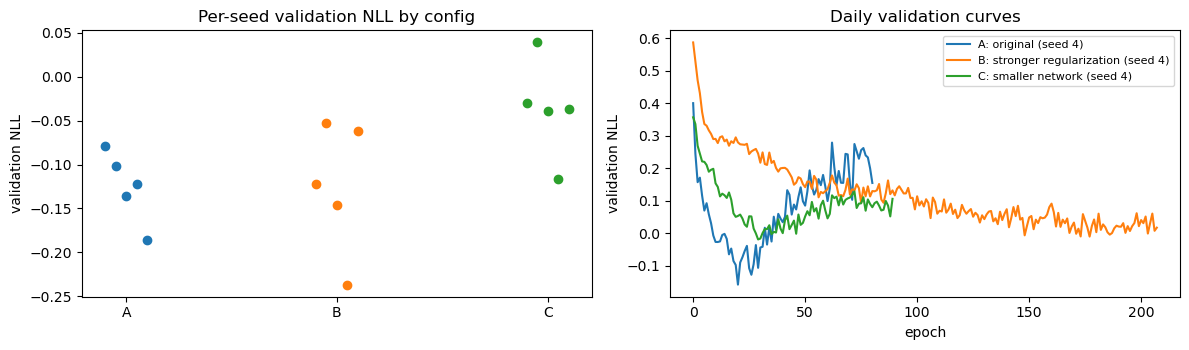

RESULT: selected B: stronger regularization; test NLL -0.142, Brier 0.0638 vs Stage 1 (3 seeds, moment-matched) NLL -0.120, Brier 0.0631; per-seed val NLL sd: A 0.036, B 0.067, C 0.049


In [16]:
D_CONFIGS = {
    "A: original":                 dict(units=(16,), dense=8, dropout=0.3, l2=1e-3, lr=3e-3, patience=60),
    "B: stronger regularization":  dict(units=(16,), dense=8, dropout=0.4, l2=1e-2, lr=1e-3, patience=30),
    "C: smaller network":          dict(units=(8,), dense=4, dropout=0.3, l2=1e-3, lr=3e-3, patience=60),
}
N_SEEDS = 5
d_runs = {}
for name, cfg in D_CONFIGS.items():
    runs = []
    for s in range(N_SEEDS):
        if name.startswith("A") and s < len(ds["runs"][7]["t"]):
            runs.append(ds["runs"][7]["t"][s])           # identical settings: reuse the Stage 1 run
        else:
            runs.append(run_daily_cfg(dly, seed=s, **cfg))
    d_runs[name] = runs
    print(f"{name}: {N_SEEDS} seeds ready")

rows = []
for name, runs in d_runs.items():
    va_nll = []
    for r in runs:
        va = r["masks"][1]
        va_nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"])
    best_ep = [int(np.argmin(r["hist"]["val_loss"])) + 1 for r in runs]
    row = {"config": name, "val NLL per seed (mean)": np.mean(va_nll), "val NLL per seed (sd)": np.std(va_nll),
           "best epoch (median)": np.median(best_ep), "best epochs": best_ep}
    for lab, rg in DRNG.items():
        for k_ in (3, N_SEEDS):
            comps = comps_on(runs[:k_], rg); idx = comps[0].index; y = dly["y"].loc[idx].values * 100
            mm = mix_metrics(y, comps)
            row[f"{lab} NLL ({k_}-seed mixture)"] = mm["NLL"]
            if k_ == N_SEEDS:
                row[f"{lab} CRPS"] = mm["CRPS"]
                cm = E.contract_metrics(price_ladder_mix(dcon[dcon.date.isin(idx)], comps))
                row[f"{lab} Brier"], row[f"{lab} accuracy"] = cm["brier"], cm["accuracy"]
    rows.append(row)
d_tab = pd.DataFrame(rows).set_index("config")
display(d_tab.round(4))

chosen = d_tab[f"val NLL ({N_SEEDS}-seed mixture)"].idxmin()
print(f"Selected on validation NLL ({N_SEEDS}-seed mixture): {chosen}")
REV["r5_daily_configs"], REV["r5_chosen"] = d_tab, chosen

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (name, runs) in enumerate(d_runs.items()):
    va_nll = [E.dist_metrics(r["y"][r["masks"][1]] * 100, r["dist"][r["masks"][1]])["NLL"] for r in runs]
    ax[0].scatter(np.full(len(va_nll), i) + np.linspace(-0.1, 0.1, len(va_nll)), va_nll)
    h = runs[-1]["hist"]; ax[1].plot(h["val_loss"], label=f"{name} (seed {N_SEEDS - 1})")
ax[0].set_xticks(range(len(d_runs))); ax[0].set_xticklabels([n.split(":")[0] for n in d_runs]); ax[0].set_ylabel("validation NLL")
ax[0].set_title("Per-seed validation NLL by config")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation NLL"); ax[1].set_title("Daily validation curves"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

stage1 = ds["table"].set_index(["split", "model"]).loc[("test", "GARCH-LSTM-t lb7 (x3)")]
print(f"RESULT: selected {chosen}; test NLL {d_tab.loc[chosen, 'test NLL (5-seed mixture)']:.3f}, Brier "
      f"{d_tab.loc[chosen, 'test Brier']:.4f} vs Stage 1 (3 seeds, moment-matched) NLL {stage1['NLL']:.3f}, Brier {stage1['brier']:.4f}; "
      f"per-seed val NLL sd: " + ", ".join(f"{n.split(':')[0]} {d_tab.loc[n, 'val NLL per seed (sd)']:.3f}" for n in d_tab.index))

### Revision log (for the contribution table)

| Date | Owner | What |
|---|---|---|
| 2026-10-23 | Wenjun Chen | Revision 1: validation-fitted and rolling scale calibration; coverage at 50/80/90/95% |
| 2026-10-23 | Wenjun Chen | Revision 2: ECM-GARCH-t baseline (weekly and daily) |
| 2026-10-23 | Wenjun Chen | Revision 3: exact seed-mixture scoring vs moment matching |
| 2026-10-23 | Wenjun Chen | Revision 4: Diebold–Mariano tests with Holm correction |
| 2026-10-23 | Wenjun Chen | Revision 5: daily model with 5 seeds and three regularization configurations |
| 2026-11-04 | Wenjun Chen | Data update: AAA daily series extended to Jun 2015 – Nov 2026 from Wayback snapshots of gasprices.aaa.com (367 → 3,865 days); daily test window fixed at Aug 20 – Oct 19 2026; notebook rerun and daily readings in Stage 1 and Revisions 2–5 rewritten |

#### ▶ What the next cell does: save the revision tables

Saves the tables collected in `REV` to `results/part2_revisions.pkl`. Parts 3 and 4 do not read this file; it is only a record of the revision results.

**Output:** the saved file path.

In [17]:
H.save("part2_revisions", {k: v for k, v in REV.items()})   # revision tables only; Parts 3-4 do not read this file

saved results/part2_revisions.pkl for the next part (data fingerprint 858e9b7a18fc)


#### ▶ What the next cell does: hand the Stage 1 results to Parts 3 and 4

Saves the weekly feature frame (`w`) and all Stage 1 forecast distributions (`res`) to `results/part2.pkl`, together with the data fingerprint. Part 3 and Part 4 load this file instead of rebuilding Part 2. This cell is unchanged from the original notebook; the revisions do not alter what is handed on.

**Output:** the saved file path.

In [18]:
H.save("part2", {"w": s1["w"], "res": s1["res"]})  # hands the results to Parts 3 and 4

saved results/part2.pkl for the next part (data fingerprint 858e9b7a18fc)
